In [3]:
import pandas as pd
import seaborn as sns

def calculate_grouped_average(df, average_column, group_by_columns):
    """
    Calculate the average of a specified column in a dataframe based on grouping columns.

    Parameters:
        df (pd.DataFrame): The input dataframe.
        average_column (str): The name of the column to calculate the average for.
        group_by_columns (list of str): The column names to group by.

    Returns:
        pd.DataFrame: A new dataframe containing the grouping columns and the calculated average.
    """
    # Group by the specified columns and calculate the mean
    grouped_df = (
        df.groupby(group_by_columns, as_index=False)
        .agg({average_column: 'mean'})
        .rename(columns={average_column: f'Super {average_column}'})
    )
    return grouped_df


In [4]:
# Function to compute jittered x-positions
def compute_jittered_x(data, x_col, order, jitter=0.1, dodge=True, dodge_width=0.4):
    x_positions = []
    for i, category in enumerate(order):
        mask = data[x_col] == category
        n_points = mask.sum()
        if n_points == 0:
            continue
        base_x = i + (dodge_width if dodge else 0)
        jittered = base_x + np.random.uniform(-jitter, jitter, n_points)
        x_positions.extend(jittered)
    return np.array(x_positions)
import numpy as np

def plot_open_circles_with_hue(ax, data, x, y, hue, order=None, hue_order=None,
                               size=20, linewidth=2, dodge=True,
                               marker='o', edgecolor='black', zorder=8,
                               jitter=False, jitter_strength=0.06, random_state=None):
    """
    Plot open circle markers on a categorical axis with hue and dodge, aligned with a seaborn plot.

    Parameters:
    - ax: Matplotlib axes object
    - data: DataFrame with the data to plot
    - x: Column name for x-axis
    - y: Column name for y-axis
    - hue: Column name for hue
    - order: List of x-axis categories
    - hue_order: List of hue categories
    - size: Marker size
    - linewidth: Outline thickness
    - dodge: Boolean to separate points by hue
    - marker: Marker style
    - edgecolor: Outline color
    - zorder: Plotting order
    - jitter: Whether to add x-axis jitter
    - jitter_strength: Magnitude of horizontal jitter
    - random_state: Seed for reproducibility
    """
    rng = np.random.default_rng(random_state)

    # Filter data to only include x values in order
    if order is not None:
        data = data[data[x].isin(order)].copy()

    # Set defaults
    if order is None:
        order = list(data[x].dropna().unique())
    if hue_order is None:
        hue_order = list(data[hue].dropna().unique())

    n_hue = len(hue_order)
    bar_width = 0.8 / n_hue if n_hue > 1 and dodge else 0.8

    for i, x_cat in enumerate(order):
        for j, hue_cat in enumerate(hue_order):
            subset = data[(data[x] == x_cat) & (data[hue] == hue_cat)]
            if subset.empty:
                continue

            # Base x-position with dodge
            if dodge and n_hue > 1:
                x_pos = i + (j - (n_hue - 1) / 2) * bar_width
            else:
                x_pos = i

            y_vals = subset[y].values

            # Add optional jitter
            if jitter:
                x_vals = x_pos + rng.uniform(-jitter_strength, jitter_strength, size=len(y_vals))
            else:
                x_vals = np.full(len(y_vals), x_pos)

            ax.scatter(
                x_vals,
                y_vals,
                facecolors='gainsboro',
                edgecolors=edgecolor,
                s=size**2,
                linewidths=linewidth,
                marker=marker,
                zorder=zorder,
                label=hue_cat if i == 0 else None
            )

    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(order, fontsize=40, rotation=75)
    
blue_palette = sns.color_palette(["#00D8D8", "#029090", "#67FFFF"])
magenta_palette = sns.color_palette(["#Ef1EEF", "#B700B7", "#FF99FF"])

In [5]:
import numpy as np
import pandas as pd
from itertools import combinations
from scipy.stats import ttest_ind

def print_ttest_summary(
    data,
    x, y,
    hue=None,
    order=None,
    hue_order=None,
    test_func=ttest_ind,
    equal_var=False,
    alternative="two-sided",
    star_thresholds=((1e-4,"****"), (1e-3,"***"), (1e-2,"**"), (5e-2,"*")),
    hide_ns=False,
    format_p=lambda p: f"{p:.3g}",
    printer=print,
    verbose=False
):
    """
    Compute and print t-tests comparing:
      - If hue is None: each x level vs the baseline (first x).
      - If hue is given:
          (A) Across x within each hue: baseline x vs each other x.
          (B) Across hue within each x: baseline hue vs each other hue.

    Returns
    -------
    results_df : pandas.DataFrame
        Columns:
        ['test_group', 'contrast', 'x0', 'x1', 'hue0', 'hue1',
         'n0', 'n1', 'pvalue', 'stars']
    """

    df = data.copy()

    # Determine levels / orders
    if order is None:
        x_levels = list(df[x].dropna().unique())
    else:
        x_levels = list(order)

    if hue is None:
        h_levels = [None]
    else:
        if hue_order is None:
            h_levels = list(df[hue].dropna().unique())
        else:
            h_levels = list(hue_order)

    # Helpers
    def p_to_stars(p):
        for thr, lab in star_thresholds:
            if p < thr:
                return lab
        return "ns"

    def _vals_for(xv, hv):
        sel = (df[x] == xv)
        if hv is not None:
            sel &= (df[hue] == hv)
        vals = df.loc[sel, y].astype(float).dropna().values
        return vals

    results = []

    # --- Case 1: No hue -> compare baseline x vs other x ---
    if hue is None:
        if len(x_levels) < 2:
            if verbose:
                printer("Not enough x levels to compare.")
            return pd.DataFrame(columns=[
                'test_group','contrast','x0','x1','hue0','hue1','n0','n1','pvalue','stars'
            ])

        base_x = x_levels[0]
        base_vals = _vals_for(base_x, None)
        if base_vals.size == 0 and verbose:
            printer(f"[warn] Baseline '{base_x}' has no data. Skipping.")

        for xv in x_levels[1:]:
            comp_vals = _vals_for(xv, None)
            if base_vals.size == 0 or comp_vals.size == 0:
                if verbose:
                    printer(f"[skip] {base_x} vs {xv}: missing data.")
                continue
            p = float(test_func(base_vals, comp_vals, equal_var=equal_var, alternative=alternative).pvalue)
            stars = p_to_stars(p)
            if not (hide_ns and stars == "ns"):
                line = f"{base_x} vs {xv}: n={base_vals.size}/{comp_vals.size}, p={format_p(p)}, {stars}"
                printer(line)
            results.append({
                'test_group': 'x|baseline',
                'contrast': f"{base_x} vs {xv}",
                'x0': base_x, 'x1': xv,
                'hue0': None, 'hue1': None,
                'n0': int(base_vals.size), 'n1': int(comp_vals.size),
                'pvalue': p, 'stars': stars
            })

    # --- Case 2: With hue ---
    else:
        # (A) Across x within each hue: baseline x vs others
        base_x = x_levels[0]
        header_printed = False
        for hv in h_levels:
            base_vals = _vals_for(base_x, hv)
            comps_exist = False
            for xv in x_levels[1:]:
                comp_vals = _vals_for(xv, hv)
                if base_vals.size == 0 or comp_vals.size == 0:
                    if verbose:
                        printer(f"[skip] [hue={hv}] {base_x} vs {xv}: missing data.")
                    continue
                if not header_printed:
                    printer("Across x (within hue):")
                    header_printed = True
                comps_exist = True
                p = float(test_func(base_vals, comp_vals, equal_var=equal_var, alternative=alternative).pvalue)
                stars = p_to_stars(p)
                if not (hide_ns and stars == "ns"):
                    line = f"[hue={hv}] {base_x} vs {xv}: n={base_vals.size}/{comp_vals.size}, p={format_p(p)}, {stars}"
                    printer(line)
                results.append({
                    'test_group': 'x|within_hue',
                    'contrast': f"[hue={hv}] {base_x} vs {xv}",
                    'x0': base_x, 'x1': xv,
                    'hue0': hv, 'hue1': hv,
                    'n0': int(base_vals.size), 'n1': int(comp_vals.size),
                    'pvalue': p, 'stars': stars
                })
            if verbose and not comps_exist:
                printer(f"[info] No valid x comparisons for hue={hv} (insufficient data).")

        # (B) Across hue within each x: baseline hue vs others
        if len(h_levels) >= 2:
            base_h = h_levels[0]
            header_printed = False
            for xv in x_levels:
                base_vals = _vals_for(xv, base_h)
                comps_exist = False
                for hv in h_levels[1:]:
                    comp_vals = _vals_for(xv, hv)
                    if base_vals.size == 0 or comp_vals.size == 0:
                        if verbose:
                            printer(f"[skip] [x={xv}] {base_h} vs {hv}: missing data.")
                        continue
                    if not header_printed:
                        printer("\nAcross hue (within x):")
                        header_printed = True
                    comps_exist = True
                    p = float(test_func(base_vals, comp_vals, equal_var=equal_var, alternative=alternative).pvalue)
                    stars = p_to_stars(p)
                    if not (hide_ns and stars == "ns"):
                        line = f"[x={xv}] {base_h} vs {hv}: n={base_vals.size}/{comp_vals.size}, p={format_p(p)}, {stars}"
                        printer(line)
                    results.append({
                        'test_group': 'hue|within_x',
                        'contrast': f"[x={xv}] {base_h} vs {hv}",
                        'x0': xv, 'x1': xv,
                        'hue0': base_h, 'hue1': hv,
                        'n0': int(base_vals.size), 'n1': int(comp_vals.size),
                        'pvalue': p, 'stars': stars
                    })
                if verbose and not comps_exist:
                    printer(f"[info] No valid hue comparisons for x={xv} (insufficient data).")

    # Build DataFrame to return
    results_df = pd.DataFrame(results, columns=[
        'test_group','contrast','x0','x1','hue0','hue1','n0','n1','pvalue','stars'
    ])

    return results_df


In [6]:
import pandas as pd
import numpy as np
from typing import Tuple, List, Optional

def scale_by_reference(
    df: pd.DataFrame,
    value_cols: Tuple[str, str],
    ref_group: str,
    ref_type: str,
    *,
    group_col: str = "Experimental Group",
    type_col: str = "Experimental Type",
    rep_col: str = "Replicate Number",
    bad_rep: Optional[int] = None
) -> pd.DataFrame:
    """
    Scale rows in `ref_group` (across all types) by per-replicate means of the reference (ref_group, ref_type).

    Steps:
      1) If bad_rep is provided: remove rows with (ref_group, ref_type, bad_rep) and
         renumber ONLY within (ref_group, ref_type): any replicate > bad_rep is decremented by 1.
      2) Compute per-replicate means of `value_cols` for (ref_group, ref_type) AFTER the optional renumbering.
      3) Merge those means onto all rows of `ref_group` by replicate and scale the given `value_cols`.
    
    Returns:
      DataFrame containing:
        - identifiers: group, type, replicate, fov (if present)
        - scaled columns for each of `value_cols`, named "<original> (scaled)"
    """
    v1, v2 = value_cols
    work = df.copy()

    # Ensure replicate is Int64
    work[rep_col] = pd.to_numeric(work[rep_col], errors="coerce").astype("Int64")

    # Masks
    mask_ref_type = (work[group_col] == ref_group) & (work[type_col] == ref_type)
    mask_group = (work[group_col] == ref_group)

    # 1) Remove bad replicate ONLY for the reference group+type, then renumber ONLY there
    if bad_rep is not None:
        # drop bad replicate
        work = work.loc[~(mask_ref_type & (work[rep_col] == bad_rep))].copy()
        # recompute mask after slicing
        mask_ref_type = (work[group_col] == ref_group) & (work[type_col] == ref_type)
        # shift 3->2, 4->3, ... only within ref group+type
        sel = mask_ref_type & (work[rep_col] > bad_rep)
        work.loc[sel, rep_col] = work.loc[sel, rep_col] - 1

    # 2) Per-replicate reference means (after potential renumber)
    ref_means = (
        work.loc[mask_ref_type]
            .groupby(rep_col)[[v1, v2]]
            .mean()
            .rename(columns={v1: f"__ref_mean__{v1}", v2: f"__ref_mean__{v2}"})
            .replace({0: np.nan})  # avoid divide-by-zero
    )

    # 3) Merge means onto all rows in the reference group (across all types), scale
    merged = work.loc[mask_group].merge(ref_means, left_on=rep_col, right_index=True, how="left")

    merged[f"{v1} (scaled)"] = merged[v1] / merged[f"__ref_mean__{v1}"]
    merged[f"{v2} (scaled)"] = merged[v2] / merged[f"__ref_mean__{v2}"]

    # Prepare output columns
    id_cols: List[str] = [group_col, type_col, rep_col]
    if "fov" in merged.columns:
        id_cols.insert(1, "fov")  # keep fov if present

    out_cols = id_cols + [f"{v1} (scaled)", f"{v2} (scaled)"]
    return merged[out_cols].copy()


In [7]:
import pandas as pd
import numpy as np
import unicodedata

def detect_and_drop_replicate_outliers(
    df,
    *,
    col_group="Experimental Group",
    col_type="Experimental Type",
    col_rep="Replicate Number",
    col_trnl="Average Total Translation Spots (scaled)",
    col_rna="Average Total RNA Spots (scaled)",
    iqr_k=1.5,
    mad_thresh=3.5,
    print_summary=True,
    manual_drop=None,      # e.g., {"No Nsp1":[2,3], "Nsp1":[4]}
    drop_mode="auto",      # "auto" | "manual" | "both" | "none"
):
    """
    Detect replicate-level outliers within each (Group×Type), label them (in outlier_df),
    and drop rows according to drop_mode.

    Auto drop (when enabled): remove flagged replicates across ALL Types within the same Group (Group×Rep).
    Manual drop (when enabled): drop any (Type×Rep) pairs across ALL Groups (string-normalized Type match).

    Returns
    -------
    outlier_df : DataFrame with [group, type, rep, mean_translation, mean_rna, outlier(str), is_outlier_either(bool)]
    data_clean : Original df with requested rows removed per drop_mode.
    """
    data = df.copy()

    # --- dtype hygiene ---
    data[col_rep] = pd.to_numeric(data[col_rep], errors="coerce").astype("Int64")
    for c in (col_trnl, col_rna):
        data[c] = pd.to_numeric(data[c], errors="coerce")

    # --- Replicate means per Group×Type ---
    rep_means = (
        data.groupby([col_group, col_type, col_rep], dropna=False)[[col_trnl, col_rna]]
            .mean()
            .reset_index()
            .rename(columns={col_trnl: "mean_translation", col_rna: "mean_rna"})
    )

    # --- Outlier detection ---
    def _iqr_fences(x, k=iqr_k):
        q1, q3 = np.nanpercentile(x, [25, 75])
        iqr = q3 - q1
        return q1 - k*iqr, q3 + k*iqr

    def _mad_z(x):
        med = np.nanmedian(x)
        mad = np.nanmedian(np.abs(x - med))
        if mad == 0 or np.isnan(mad):
            return np.full_like(x, np.nan, dtype=float)
        return 0.6745 * (x - med) / mad

    def per_block(block):
        x_t = block["mean_translation"].to_numpy()
        x_r = block["mean_rna"].to_numpy()
        lo_t, hi_t = _iqr_fences(x_t); lo_r, hi_r = _iqr_fences(x_r)
        mz_t, mz_r = _mad_z(x_t), _mad_z(x_r)
        is_t = ((x_t < lo_t) | (x_t > hi_t)) | (np.abs(mz_t) > mad_thresh)
        is_r = ((x_r < lo_r) | (x_r > hi_r)) | (np.abs(mz_r) > mad_thresh)
        block["is_outlier_either"] = is_t | is_r
        return block

    flagged = (
        rep_means.groupby([col_group, col_type], group_keys=False)
                 .apply(per_block)
                 .reset_index(drop=True)
    )

    # --- outlier_df (includes ALL reps + label) ---
    outlier_df = flagged[[col_group, col_type, col_rep, "mean_translation", "mean_rna", "is_outlier_either"]].copy()
    outlier_df["outlier"] = np.where(outlier_df["is_outlier_either"], "outlier", "")

    # === Build drop masks per mode ===
    # Auto: across ALL types within a Group → keys = (Group, Rep)
    bad_grp_rep_set = set()
    if drop_mode in ("auto", "both"):
        bad_grp_rep = (
            outlier_df.loc[outlier_df["is_outlier_either"], [col_group, col_rep]]
                      .drop_duplicates()
        )
        bad_grp_rep[col_rep] = pd.to_numeric(bad_grp_rep[col_rep], errors="coerce").astype("Int64")
        bad_grp_rep_set = set(map(tuple, bad_grp_rep[[col_group, col_rep]].itertuples(index=False, name=None)))

    # Manual: across ALL groups for (Type, Rep) pairs; normalize type strings
    def _norm_type(x):
        if pd.isna(x): return np.nan
        x = unicodedata.normalize("NFKC", str(x))
        return x.strip().lower()

    bad_type_rep_set = set()
    if drop_mode in ("manual", "both") and manual_drop:
        pairs = [(_norm_type(t), int(r)) for t, reps in manual_drop.items() for r in reps]
        manual_df = pd.DataFrame(pairs, columns=[col_type, col_rep])
        manual_df[col_rep] = pd.to_numeric(manual_df[col_rep], errors="coerce").astype("Int64")
        bad_type_rep_set = set(map(tuple, manual_df[[col_type, col_rep]].itertuples(index=False, name=None)))

    # Prepare row-wise keys
    type_key = data[col_type].map(_norm_type)
    grp_rep_tuples  = pd.Series(list(zip(data[col_group], data[col_rep])), index=data.index)
    type_rep_tuples = pd.Series(list(zip(type_key, data[col_rep])), index=data.index)

    auto_mask   = grp_rep_tuples.isin(bad_grp_rep_set)   if bad_grp_rep_set else pd.Series(False, index=data.index)
    manual_mask = type_rep_tuples.isin(bad_type_rep_set) if bad_type_rep_set else pd.Series(False, index=data.index)

    if drop_mode == "auto":
        mask_drop = auto_mask
    elif drop_mode == "manual":
        mask_drop = manual_mask
    elif drop_mode == "both":
        mask_drop = auto_mask | manual_mask
    elif drop_mode == "none":
        mask_drop = pd.Series(False, index=data.index)
    else:
        raise ValueError("drop_mode must be one of: 'auto', 'manual', 'both', 'none'")

    data_clean = data.loc[~mask_drop].reset_index(drop=True)

    if print_summary:
        if drop_mode in ("auto", "both"):
            flagged_rows = outlier_df[outlier_df["is_outlier_either"]]
            if flagged_rows.empty:
                print("No replicate-level outliers detected.")
            else:
                for (g, t), sub in flagged_rows.groupby([col_group, col_type]):
                    reps = ", ".join(str(int(r)) for r in sub[col_rep].tolist())
                    print(f"[{g} | {t}] Outlier replicate(s): {reps}")
        if drop_mode in ("manual", "both") and manual_drop:
            print("\nManual drop requested for (Type → Replicates):")
            for t, reps in manual_drop.items():
                print(f"  {t}: {sorted(reps)}")
        print(f"\nDrop mode: {drop_mode}. Rows removed: {int(mask_drop.sum())}")

    return outlier_df, data_clean


In [8]:
import pandas as pd
import numpy as np

def detect_and_drop_cell_outliers_by_fov(
    df,
    *,
    col_group="Experimental Group",
    col_type="Experimental Type",
    col_rep="Replicate Number",
    col_fov="fov",
    col_trnl="Average Total Translation Spots",
    col_rna="Average Total RNA Spots",
    iqr_k=1.5,
    print_summary=True,
):
    """
    Find per-cell (Group×Type×Replicate×FOV) outliers for Translation & RNA using Tukey IQR
    computed within each (Group×Type) block (across all replicates & FOVs in that block).
    Remove ALL rows from the input df that belong to any outlier cell (same Group, Type, Rep, FOV).

    Returns
    -------
    outlier_cells : DataFrame with means and flags for every cell (plus 'outlier' string)
    df_clean      : Original df with outlier cells removed
    """
    data = df.copy()

    # Coerce IDs and values
    for c in (col_rep, col_fov):
        data[c] = pd.to_numeric(data[c], errors="coerce").astype("Int64")
    for c in (col_trnl, col_rna):
        data[c] = pd.to_numeric(data[c], errors="coerce")

    # 1) Per-cell means (averages across any duplicates like 'Location')
    cell_means = (
        data.groupby([col_group, col_type, col_rep, col_fov], dropna=False)[[col_trnl, col_rna]]
            .mean()
            .reset_index()
            .rename(columns={col_trnl: "cell_mean_translation", col_rna: "cell_mean_rna"})
    )

    # 2) Outlier detection per (Group×Type)
    def iqr_bounds(x, k=iqr_k):
        q1, q3 = np.nanpercentile(x, [25, 75])
        iqr = q3 - q1
        return q1 - k*iqr, q3 + k*iqr

    def flag_block(block):
        lo_t, hi_t = iqr_bounds(block["cell_mean_translation"].to_numpy())
        lo_r, hi_r = iqr_bounds(block["cell_mean_rna"].to_numpy())
        block["is_out_trnl"] = (block["cell_mean_translation"] < lo_t) | (block["cell_mean_translation"] > hi_t)
        block["is_out_rna"]  = (block["cell_mean_rna"] < lo_r) | (block["cell_mean_rna"] > hi_r)
        block["is_out_any"]  = block["is_out_trnl"] | block["is_out_rna"]
        return block

    cell_flagged = (
        cell_means.groupby([col_group, col_type], group_keys=False)
                  .apply(flag_block)
                  .reset_index(drop=True)
    )

    # 3) Tidy outlier table (includes ALL cells + a simple string column)
    outlier_cells = cell_flagged.copy()
    outlier_cells["outlier"] = np.where(outlier_cells["is_out_any"], "outlier", "")

    # Optional printout
    if print_summary:
        hits = outlier_cells[outlier_cells["is_out_any"]]
        if hits.empty:
            print("No per-cell outliers detected.")
        else:
            for _, r in hits.sort_values([col_group, col_type, col_rep, col_fov]).iterrows():
                which = " & ".join([w for w, ok in (("Translation", r["is_out_trnl"]),
                                                     ("RNA", r["is_out_rna"])) if ok])
                print(f"{r[col_group]} | {r[col_type]} | fov {r[col_fov]} | rep {r[col_rep]} is outlier ({which})")

    # 4) Drop outlier cells from original df
    keys_to_drop = (
        outlier_cells.loc[outlier_cells["is_out_any"], [col_group, col_type, col_rep, col_fov]]
                     .drop_duplicates()
    )
    # align dtypes
    for c in (col_rep, col_fov):
        keys_to_drop[c] = pd.to_numeric(keys_to_drop[c], errors="coerce").astype("Int64")

    df_clean = (
        data.merge(keys_to_drop.assign(_drop=1),
                   on=[col_group, col_type, col_rep, col_fov],
                   how="left")
            .loc[lambda d: d["_drop"].isna()]
            .drop(columns="_drop")
            .reset_index(drop=True)
    )

    return outlier_cells, df_clean


In [9]:
def bootstrap_ci_mean(x, n_boot=1000, ci=95, seed=None):
    x = np.asarray(x, float)
    x = x[~np.isnan(x)]
    if x.size == 0:
        return np.nan, np.nan
    rng = np.random.default_rng(seed)  # seaborn also uses default_rng
    # resample rows, compute mean per resample
    boots = rng.choice(x, size=(n_boot, x.size), replace=True)
    stats = boots.mean(axis=1)
    alpha = (100 - ci) / 2
    lo = np.percentile(stats, alpha)
    hi = np.percentile(stats, 100 - alpha)
    return lo, hi

In [10]:


def seaborn_like_bar_stats(
    data,
    col,
    category_col="Experimental Type",
    order=None,
    ref_type=None,
    n_boot=1000,
    ci=95,
):
    """
    Compute bar heights (means) and asymmetric 95% bootstrap CIs per category,
    matching seaborn’s default behavior. Reference category gets 0 error.
    
    Returns:
        means: np.array shape (k,)
        yerr:  np.array shape (2, k)  # [lower_errs; upper_errs]
        cats:  list of category labels in returned order
        stats: pd.DataFrame with per-category stats (mean, n, lo, hi, lower_err, upper_err)
    """
    # Determine category order
    if order is None:
        cats = list(pd.Series(data[category_col]).dropna().unique())
    else:
        cats = list(order)

    means, lower_errs, upper_errs, rows = [], [], [], []
    for cat in cats:
        vals = data.loc[data[category_col] == cat, col].dropna().to_numpy(float)
        m = float(np.mean(vals)) if vals.size else np.nan

        if (ref_type is not None and cat == ref_type) or vals.size == 0:
            lo = hi = m
            lower = upper = 0.0
        else:
            lo, hi = bootstrap_ci_mean(vals, n_boot=n_boot, ci=ci, seed=None)
            lower = m - lo
            upper = hi - m

        means.append(m)
        lower_errs.append(lower)
        upper_errs.append(upper)
        rows.append({
            "category": cat, "n": vals.size, "mean": m,
            "ci_low": lo, "ci_high": hi,
            "lower_err": lower, "upper_err": upper
        })

    means = np.asarray(means, float)
    yerr = np.vstack([np.asarray(lower_errs, float), np.asarray(upper_errs, float)])
    stats = pd.DataFrame(rows)
    return means, yerr, cats, stats

In [11]:
from pathlib import Path
import pandas as pd
import re
from typing import List

In [12]:

ROOT_DIR = Path(r"Z:\SharedInternal\People\forAdam\NSP1_Data_ForAdam\Data Files")

# File name patterns used to identify each file type
CELL_TOTALS_PATTERNS = [
    "cell_totals"
]

CELLID_TRANS_PATTERNS = [
    "cellid_t",
]

FILE_EXTENSIONS = {".csv"}

print("Root directory:", ROOT_DIR)
print("Exists:", ROOT_DIR.exists())

Root directory: Z:\SharedInternal\People\forAdam\NSP1_Data_ForAdam\Data Files
Exists: True


In [13]:
def extract_date_from_folder(folder_name: str) -> str:
    """
    Extract a date from folder names like:
    Expt_2024-08-16
    Expt_2024_08_16
    Expt_20240816

    Returns a standardized YYYY-MM-DD string when possible.
    If no date is found, returns the folder name.
    """
    match = re.search(r"(\d{4})[-_](\d{2})[-_](\d{2})", folder_name)
    if match:
        y, m, d = match.groups()
        return f"{y}-{m}-{d}"

    match = re.search(r"(\d{4})(\d{2})(\d{2})", folder_name)
    if match:
        y, m, d = match.groups()
        return f"{y}-{m}-{d}"

    return folder_name


def normalize_filename(file_path: Path) -> str:
    """
    Lowercase file stem for easier matching.
    """
    return file_path.stem.lower()


def file_matches_patterns(file_path: Path, patterns: List[str]) -> bool:
    """
    Check whether a file name contains any of the target patterns.
    """
    name = normalize_filename(file_path)
    return any(pattern in name for pattern in patterns)


def find_matching_csv_files(folder: Path, patterns: List[str]) -> List[Path]:
    """
    Find CSV files directly inside a folder that match the given patterns.
    """
    matches = []
    for file_path in folder.iterdir():
        if file_path.is_file() and file_path.suffix.lower() in FILE_EXTENSIONS:
            if file_matches_patterns(file_path, patterns):
                matches.append(file_path)
    return sorted(matches)


def read_and_tag_csv(file_path: Path, expt_folder: str, expt_date: str) -> pd.DataFrame:
    """
    Read a CSV file and add metadata columns.
    """
    df = pd.read_csv(file_path)
    df["Date"] = expt_date
    df["Expt_Folder"] = expt_folder
    df["Source_File"] = file_path.name
    return df

In [14]:
# Find all experiment folders
# -----------------------------
if not ROOT_DIR.exists():
    raise FileNotFoundError(f"Root directory does not exist: {ROOT_DIR}")

expt_folders = sorted([p for p in ROOT_DIR.iterdir() if p.is_dir()])

print(f"Found {len(expt_folders)} experiment folders.")
for folder in expt_folders[:10]:
    print(folder.name)

Found 6 experiment folders.
Expt_250404
Expt_250505
Expt_250626
Expt_250716
Expt_250724
Expt_250808


In [15]:
# Scan each experiment folder
# -----------------------------
summary_rows = []
cell_totals_files_all = []
cellid_trans_files_all = []

for folder in expt_folders:
    expt_folder = folder.name
    expt_date = extract_date_from_folder(expt_folder)

    cell_totals_files = find_matching_csv_files(folder, CELL_TOTALS_PATTERNS)
    cellid_trans_files = find_matching_csv_files(folder, CELLID_TRANS_PATTERNS)

    for fp in cell_totals_files:
        cell_totals_files_all.append({
            "file_path": fp,
            "Date": expt_date,
            "Expt_Folder": expt_folder,
            "File_Type": "cell_totals"
        })

    for fp in cellid_trans_files:
        cellid_trans_files_all.append({
            "file_path": fp,
            "Date": expt_date,
            "Expt_Folder": expt_folder,
            "File_Type": "cellid_trans"
        })

    summary_rows.append({
        "Expt_Folder": expt_folder,
        "Date": expt_date,
        "n_cell_totals_files": len(cell_totals_files),
        "n_cellid_trans_files": len(cellid_trans_files),
    })

summary_df = pd.DataFrame(summary_rows)
summary_df.head()

,Expt_Folder,Date,n_cell_totals_files,n_cellid_trans_files
0,Expt_250404,Expt_250404,1,1
1,Expt_250505,Expt_250505,1,1
2,Expt_250626,Expt_250626,1,1
3,Expt_250716,Expt_250716,1,1
4,Expt_250724,Expt_250724,1,1


In [16]:
# Load all cell totals files
# -----------------------------
cell_totals_dfs = []

for item in cell_totals_files_all:
    fp = item["file_path"]
    expt_folder = item["Expt_Folder"]
    expt_date = item["Date"]

    try:
        df = read_and_tag_csv(fp, expt_folder, expt_date)
        cell_totals_dfs.append(df)
    except Exception as e:
        print(f"Could not read cell totals file: {fp}")
        print("Error:", e)

df_cell_totals_all = (
    pd.concat(cell_totals_dfs, ignore_index=True)
    if cell_totals_dfs else pd.DataFrame()
)

print("df_cell_totals_all shape:", df_cell_totals_all.shape)
df_cell_totals_all

df_cell_totals_all shape: (1281, 56)


,Unnamed: 0,image,ocellid,trans_cnt,trans_final_cnt,cytrna1,total_rna_cnt,cytrna_pct,nucrna_pct,pct_cyt_trans,...,Date,Expt_Folder,Source_File,cell_zproj_label,cell_zproj_area,cell_zproj_centroid-0,cell_zproj_centroid-1,nuc_cyto_ratio_C0,nuc_cyto_ratio_C1,nuc_cyto_ratio_C2
0,0,040425_Hela_E10-A3-12_CTG_Cont_Flag mAb TR_JF6...,2,22,19,41,96,42.71,57.29,46.34,...,Expt_250404,Expt_250404,cell_totals_250404.csv,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,040425_Hela_E10-A3-12_CTG_Cont_Flag mAb TR_JF6...,3,43,34,79,141,56.03,43.97,43.04,...,Expt_250404,Expt_250404,cell_totals_250404.csv,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,040425_Hela_E10-A3-12_CTG_Cont_Flag mAb TR_JF6...,5,24,23,43,109,39.45,60.55,53.49,...,Expt_250404,Expt_250404,cell_totals_250404.csv,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,040425_Hela_E10-A3-12_CTG_Cont_Flag mAb TR_JF6...,6,10,8,23,35,65.71,34.29,34.78,...,Expt_250404,Expt_250404,cell_totals_250404.csv,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,040425_Hela_E10-A3-12_CTG_Cont_Flag mAb TR_JF6...,2,8,7,30,99,30.30,69.70,23.33,...,Expt_250404,Expt_250404,cell_totals_250404.csv,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1276,205,080825_Hela_E10-A3-12_CTG_Control_24h_Flag mAb...,3,15,14,46,111,41.44,58.56,30.43,...,Expt_250808,Expt_250808,cell_totals_250808.csv,3.0,77637.0,243.363680,148.257880,8.586942,0.505330,0.691682
1277,206,080825_Hela_E10-A3-12_CTG_Control_24h_Flag mAb...,4,9,10,28,86,32.56,67.44,35.71,...,Expt_250808,Expt_250808,cell_totals_250808.csv,4.0,77972.0,445.719002,330.127341,6.857212,0.518384,0.702582
1278,207,080825_Hela_E10-A3-12_CTG_Control_24h_Flag mAb...,5,3,4,9,69,13.04,86.96,44.44,...,Expt_250808,Expt_250808,cell_totals_250808.csv,5.0,72768.0,610.841373,509.034122,10.011226,1.510100,1.716724
1279,208,080825_Hela_E10-A3-12_CTG_Control_24h_Flag mAb...,6,10,9,22,88,25.00,75.00,40.91,...,Expt_250808,Expt_250808,cell_totals_250808.csv,6.0,49367.0,561.733587,95.765917,4.401515,0.110328,0.250048


In [17]:
# Load all cellid translation files
# -----------------------------
cellid_trans_dfs = []

for item in cellid_trans_files_all:
    fp = item["file_path"]
    expt_folder = item["Expt_Folder"]
    expt_date = item["Date"]

    try:
        df = read_and_tag_csv(fp, expt_folder, expt_date)
        cellid_trans_dfs.append(df)
    except Exception as e:
        print(f"Could not read cellid trans file: {fp}")
        print("Error:", e)

df_cellid_trans_all = (
    pd.concat(cellid_trans_dfs, ignore_index=True)
    if cellid_trans_dfs else pd.DataFrame()
)

print("df_cellid_trans_all shape:", df_cellid_trans_all.shape)
df_cellid_trans_all.head()

df_cellid_trans_all shape: (173423, 96)


,Unnamed: 0,image,Z,Y,X,area_spot,area_bkg,spot_mean_c1,spotsub_mean_c1,bkg_mean_c1,...,trans,trans1,spot_bkg_r,treat,trans_s,trans_to_count,Date,Expt_Folder,Source_File,trans_to_cnt
0,0,040425_Hela_E10-A3-12_CTG_Cont_Flag mAb TR_JF6...,1,182,337,49,64,677.918367,31.043048,683.328125,...,True,True,1.786833,Control,True,True,Expt_250404,Expt_250404,cellid_trans_s_Trans_Spot_Intensity_DonutBkg_2...,NaN
1,1,040425_Hela_E10-A3-12_CTG_Cont_Flag mAb TR_JF6...,1,215,150,49,64,742.102041,55.461097,716.046875,...,True,True,1.842009,Control,True,True,Expt_250404,Expt_250404,cellid_trans_s_Trans_Spot_Intensity_DonutBkg_2...,NaN
2,2,040425_Hela_E10-A3-12_CTG_Cont_Flag mAb TR_JF6...,1,456,96,49,64,696.040816,43.807398,681.937500,...,True,True,1.435023,Control,True,True,Expt_250404,Expt_250404,cellid_trans_s_Trans_Spot_Intensity_DonutBkg_2...,NaN
3,3,040425_Hela_E10-A3-12_CTG_Cont_Flag mAb TR_JF6...,1,514,227,49,64,768.448980,29.280612,787.312500,...,False,False,0.855060,Control,False,False,Expt_250404,Expt_250404,cellid_trans_s_Trans_Spot_Intensity_DonutBkg_2...,NaN
4,4,040425_Hela_E10-A3-12_CTG_Cont_Flag mAb TR_JF6...,1,523,196,49,64,722.183673,43.080995,714.578125,...,False,False,0.656535,Control,False,False,Expt_250404,Expt_250404,cellid_trans_s_Trans_Spot_Intensity_DonutBkg_2...,NaN


In [18]:
# Rename selected values in the "treat" column
treat_rename_map = {
    "NSP-Fus": "Nsp1_Fusion",
    "NSP-P2A": "Nsp1_mCh",
    "NSP-deltaC": "delta_Nsp1",
    "NSP1-Fus": "Nsp1_Fusion",
    "NSP1-P2A": "Nsp1_mCh",
    "NSP1-P2A-GFP": "Nsp1_GFP",
    "NSP1-deltaC-mCh": "delta_Nsp1_mCh",
    "Nsp1-Fus-GFP": "Nsp1_Fusion_GFP",
    "Nsp1-P2A-GFP": "Nsp1_GFP",
}

df_cell_totals_all["treat"] = df_cell_totals_all["treat"].replace(treat_rename_map)

In [19]:
# Work from a copy so the original stays untouched
df_fixed_raw = df_cell_totals_all.copy()

required_cols = [
    "treat",
    "ocellid",
    "trans_final_cnt",
    "total_rna_cnt",
    "cytrna1",
    "Date",
    "Source_File",
]

missing_cols = [c for c in required_cols if c not in df_fixed_raw.columns]

if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

print("All required columns are present.")
print(df_fixed_raw[required_cols].head())

All required columns are present.
     treat  ocellid  trans_final_cnt  total_rna_cnt  cytrna1         Date  \
0  Control        2               19             96       41  Expt_250404   
1  Control        3               34            141       79  Expt_250404   
2  Control        5               23            109       43  Expt_250404   
3  Control        6                8             35       23  Expt_250404   
4  Control        2                7             99       30  Expt_250404   

              Source_File  
0  cell_totals_250404.csv  
1  cell_totals_250404.csv  
2  cell_totals_250404.csv  
3  cell_totals_250404.csv  
4  cell_totals_250404.csv  


In [20]:
# Correct date Time
import pandas as pd
import re

def parse_expt_date(value):
    """
    Convert strings like:
        Expt_250404
        250404
    into pandas Timestamp: 2025-04-04
    """
    if pd.isna(value):
        return pd.NaT

    value = str(value)

    # Look for 6 consecutive digits representing YYMMDD
    match = re.search(r"(\d{6})", value)
    if not match:
        return pd.NaT

    yymmdd = match.group(1)

    # Interpret as 20YY-MM-DD
    return pd.to_datetime("20" + yymmdd, format="%Y%m%d", errors="coerce")


df_fixed_raw["Date"] = df_fixed_raw["Date"].apply(parse_expt_date)

print("Corrected Date column:")
print(df_fixed_raw["Date"].head())
print("\nDate range:")
print(df_fixed_raw["Date"].min(), "to", df_fixed_raw["Date"].max())

Corrected Date column:
0   2025-04-04
1   2025-04-04
2   2025-04-04
3   2025-04-04
4   2025-04-04
Name: Date, dtype: datetime64[ns]

Date range:
2025-04-04 00:00:00 to 2025-08-08 00:00:00


In [21]:
# Create the new dataframe
df_graph_counts = df_fixed_raw.copy()

# 1. Experimental Type from treat
df_graph_counts["Experimental Type"] = df_graph_counts["treat"]

# 2. Experimental Group is constant for this dataset
df_graph_counts["Experimental Group"] = "Endogenous MyH9"

# 3. Fixed-cell data, so all timepoints are 0
df_graph_counts["t"] = 0

# 4. Count columns
df_graph_counts["Trnl Count"] = df_graph_counts["trans_final_cnt"]
df_graph_counts["Total mRNA"] = df_graph_counts["total_rna_cnt"]
df_graph_counts["Cyto mRNA"] = df_graph_counts["cytrna1"]
df_graph_counts["Nuc mRNA"] = df_graph_counts["Total mRNA"] - df_graph_counts["Cyto mRNA"]

# Optional safety check: if anything went negative, flag it
negative_nuc = (df_graph_counts["Nuc mRNA"] < 0).sum()
print(f"Rows with negative Nuc mRNA: {negative_nuc}")

Rows with negative Nuc mRNA: 0


In [22]:
# Rebuild fov so every row gets a unique cell number
# within each Date + Experimental Type group

# Keep a stable ordering before numbering
df_graph_counts = df_graph_counts.sort_values(
    by=["Date", "Experimental Type", "Source_File", "ocellid"]
).copy()

df_graph_counts["fov"] = (
    df_graph_counts.groupby(["Date", "Experimental Type"])
    .cumcount() + 1
)

print(df_graph_counts[["Date", "Experimental Type", "Source_File", "ocellid", "fov"]].head(20))

         Date Experimental Type             Source_File  ocellid  fov
8  2025-04-04           Control  cell_totals_250404.csv        1    1
23 2025-04-04           Control  cell_totals_250404.csv        1    2
29 2025-04-04           Control  cell_totals_250404.csv        1    3
32 2025-04-04           Control  cell_totals_250404.csv        1    4
37 2025-04-04           Control  cell_totals_250404.csv        1    5
40 2025-04-04           Control  cell_totals_250404.csv        1    6
0  2025-04-04           Control  cell_totals_250404.csv        2    7
4  2025-04-04           Control  cell_totals_250404.csv        2    8
12 2025-04-04           Control  cell_totals_250404.csv        2    9
19 2025-04-04           Control  cell_totals_250404.csv        2   10
24 2025-04-04           Control  cell_totals_250404.csv        2   11
30 2025-04-04           Control  cell_totals_250404.csv        2   12
33 2025-04-04           Control  cell_totals_250404.csv        2   13
38 2025-04-04       

In [23]:
# Build a date-to-replicate mapping within each Experimental Type
replicate_map = (
    df_graph_counts[["Experimental Type", "Date"]]
    .drop_duplicates()
    .sort_values(["Experimental Type", "Date"])
    .copy()
)

replicate_map["Replicate Number"] = (
    replicate_map.groupby("Experimental Type")
    .cumcount() + 1
)

# Merge back into the main dataframe
df_graph_counts = df_graph_counts.merge(
    replicate_map,
    on=["Experimental Type", "Date"],
    how="left"
)

print(replicate_map.head(20))

      Experimental Type       Date  Replicate Number
530          CA+NSP-Fus 2025-07-16                 1
723          CA+NSP-Fus 2025-07-24                 2
551          CA+NSP-P2A 2025-07-16                 1
768          CA+NSP-P2A 2025-07-24                 2
1080         CA+NSP-P2A 2025-08-08                 3
605       CA+NSP-deltaC 2025-07-16                 1
812       CA+NSP-deltaC 2025-07-24                 2
1117  CA+NSP-deltaC-GFP 2025-08-08                 1
1154  CA+NSP-deltaC-mCh 2025-08-08                 1
648                CAsi 2025-07-16                 1
851                CAsi 2025-07-24                 2
1205               CAsi 2025-08-08                 3
8               Control 2025-04-04                 1
164             Control 2025-05-05                 2
334             Control 2025-06-26                 3
678             Control 2025-07-16                 4
892             Control 2025-07-24                 5
1245            Control 2025-08-08            

In [24]:
final_columns = [
    "Experimental Group",
    "fov",
    "t",
    "Experimental Type",
    "Replicate Number",
    "Date",
    "Trnl Count",
    "Total mRNA",
    "Cyto mRNA",
    "Nuc mRNA",
    "Source_File",
]

df_graph_counts_final = df_graph_counts[final_columns].copy()

print(df_graph_counts_final.head())
df_graph_counts_final

  Experimental Group  fov  t Experimental Type  Replicate Number       Date  \
0    Endogenous MyH9    1  0           Control                 1 2025-04-04   
1    Endogenous MyH9    2  0           Control                 1 2025-04-04   
2    Endogenous MyH9    3  0           Control                 1 2025-04-04   
3    Endogenous MyH9    4  0           Control                 1 2025-04-04   
4    Endogenous MyH9    5  0           Control                 1 2025-04-04   

   Trnl Count  Total mRNA  Cyto mRNA  Nuc mRNA             Source_File  
0          19         116         54        62  cell_totals_250404.csv  
1          26         149         66        83  cell_totals_250404.csv  
2          21         144         59        85  cell_totals_250404.csv  
3          18         100         37        63  cell_totals_250404.csv  
4          27         119         67        52  cell_totals_250404.csv  


,Experimental Group,fov,t,Experimental Type,Replicate Number,Date,Trnl Count,Total mRNA,Cyto mRNA,Nuc mRNA,Source_File
0,Endogenous MyH9,1,0,Control,1,2025-04-04,19,116,54,62,cell_totals_250404.csv
1,Endogenous MyH9,2,0,Control,1,2025-04-04,26,149,66,83,cell_totals_250404.csv
2,Endogenous MyH9,3,0,Control,1,2025-04-04,21,144,59,85,cell_totals_250404.csv
3,Endogenous MyH9,4,0,Control,1,2025-04-04,18,100,37,63,cell_totals_250404.csv
4,Endogenous MyH9,5,0,Control,1,2025-04-04,27,119,67,52,cell_totals_250404.csv
...,...,...,...,...,...,...,...,...,...,...,...
1276,Endogenous MyH9,51,0,Control,6,2025-08-08,8,98,18,80,cell_totals_250808.csv
1277,Endogenous MyH9,52,0,Control,6,2025-08-08,10,63,27,36,cell_totals_250808.csv
1278,Endogenous MyH9,53,0,Control,6,2025-08-08,6,96,13,83,cell_totals_250808.csv
1279,Endogenous MyH9,54,0,Control,6,2025-08-08,8,64,18,46,cell_totals_250808.csv


In [25]:
save_path = ROOT_DIR / "Endogenous_MyH9_graphing_counts_dataframe.csv"
df_graph_counts_final.to_csv(save_path, index=False)

print(f"Saved to: {save_path}")

Saved to: Z:\SharedInternal\People\forAdam\NSP1_Data_ForAdam\Data Files\Endogenous_MyH9_graphing_counts_dataframe.csv


In [26]:
save_path = ROOT_DIR / "Endogenous_MyH9_graphing_counts_dataframe.csv"
df_graph_counts_final = pd.read_csv(save_path)

In [27]:
# Make sure Date is datetime
df_graph_counts_final["Date"] = pd.to_datetime(df_graph_counts_final["Date"])

# Define the date groups
gfp_dates = pd.to_datetime([
    "2025-04-04",
    "2025-05-05",
])

mch_dates = pd.to_datetime([
    "2025-06-26",
    "2025-07-24",
])

# Split the dataframe
all_GFP_data = df_graph_counts_final[
    df_graph_counts_final["Date"].isin(gfp_dates)
].copy()

all_mCh_data = df_graph_counts_final[
    df_graph_counts_final["Date"].isin(mch_dates)
].copy()


In [28]:
# Create a new dataframe with merged Nsp1 labels
df_graph_counts_merged = df_graph_counts_final.copy()

rename_map = {
    "Nsp1_GFP": "Nsp1",
    "Nsp1_mCh": "Nsp1",
}

df_graph_counts_merged["Experimental Type"] = (
    df_graph_counts_merged["Experimental Type"].replace(rename_map)
)

print(sorted(df_graph_counts_merged["Experimental Type"].dropna().unique()))

['CA+NSP-Fus', 'CA+NSP-P2A', 'CA+NSP-deltaC', 'CA+NSP-deltaC-GFP', 'CA+NSP-deltaC-mCh', 'CAsi', 'Control', 'Nsp1', 'Nsp1_Fusion', 'Nsp1_Fusion_GFP', 'delta_Nsp1', 'delta_Nsp1_mCh']


In [29]:
outlier_cells, df_no_outliers = detect_and_drop_cell_outliers_by_fov(
    df_graph_counts_merged,
    col_group="Experimental Group",
    col_type="Experimental Type",
    col_rep="Replicate Number",
    col_fov="fov",
    col_trnl="Trnl Count",
    col_rna="Cyto mRNA",
    iqr_k=1.5,
)
temp = df_no_outliers
temp = temp[temp["Experimental Type"].isin(["Control", "Nsp1"])]
valid_dates = (
    temp.groupby("Date")["Experimental Type"]
    .apply(lambda x: {"Control", "Nsp1"}.issubset(set(x)))
)
valid_dates = valid_dates[valid_dates].index

df_no_outliers = temp[temp["Date"].isin(valid_dates)].copy()

replicate_map = (
    pd.DataFrame({"Date": sorted(df_no_outliers["Date"].dropna().unique())})
    .reset_index(drop=True)
)

replicate_map["Replicate Number"] = replicate_map.index + 1

df_no_outliers = df_no_outliers.drop(columns=["Replicate Number"], errors="ignore").merge(
    replicate_map,
    on="Date",
    how="left"
)


Endogenous MyH9 | CA+NSP-Fus | fov 8 | rep 2 is outlier (Translation & RNA)
Endogenous MyH9 | CA+NSP-Fus | fov 16 | rep 2 is outlier (Translation)
Endogenous MyH9 | CA+NSP-Fus | fov 17 | rep 2 is outlier (Translation & RNA)
Endogenous MyH9 | CA+NSP-Fus | fov 19 | rep 2 is outlier (RNA)
Endogenous MyH9 | CA+NSP-Fus | fov 20 | rep 2 is outlier (RNA)
Endogenous MyH9 | CA+NSP-Fus | fov 26 | rep 2 is outlier (Translation & RNA)
Endogenous MyH9 | CA+NSP-Fus | fov 28 | rep 2 is outlier (Translation & RNA)
Endogenous MyH9 | CA+NSP-Fus | fov 36 | rep 2 is outlier (RNA)
Endogenous MyH9 | CA+NSP-P2A | fov 5 | rep 1 is outlier (RNA)
Endogenous MyH9 | CA+NSP-P2A | fov 8 | rep 1 is outlier (Translation)
Endogenous MyH9 | CA+NSP-P2A | fov 15 | rep 1 is outlier (RNA)
Endogenous MyH9 | CA+NSP-P2A | fov 25 | rep 1 is outlier (Translation)
Endogenous MyH9 | CA+NSP-P2A | fov 39 | rep 1 is outlier (Translation)
Endogenous MyH9 | CA+NSP-P2A | fov 1 | rep 2 is outlier (Translation)
Endogenous MyH9 | CA+NSP-P

In [30]:
outlier_cells, df_no_outliers_total = detect_and_drop_cell_outliers_by_fov(
    df_graph_counts_merged,
    col_group="Experimental Group",
    col_type="Experimental Type",
    col_rep="Replicate Number",
    col_fov="fov",
    col_trnl="Trnl Count",
    col_rna="Total mRNA",
    iqr_k=1.5,
)
temp = df_no_outliers_total
temp = temp[temp["Experimental Type"].isin(["Control", "Nsp1"])]
valid_dates = (
    temp.groupby("Date")["Experimental Type"]
    .apply(lambda x: {"Control", "Nsp1"}.issubset(set(x)))
)
valid_dates = valid_dates[valid_dates].index

df_no_outliers_total = temp[temp["Date"].isin(valid_dates)].copy()

replicate_map = (
    pd.DataFrame({"Date": sorted(df_no_outliers_total["Date"].dropna().unique())})
    .reset_index(drop=True)
)

replicate_map["Replicate Number"] = replicate_map.index + 1

df_no_outliers_total = df_no_outliers_total.drop(columns=["Replicate Number"], errors="ignore").merge(
    replicate_map,
    on="Date",
    how="left"
)

Endogenous MyH9 | CA+NSP-Fus | fov 8 | rep 2 is outlier (Translation)
Endogenous MyH9 | CA+NSP-Fus | fov 13 | rep 2 is outlier (RNA)
Endogenous MyH9 | CA+NSP-Fus | fov 16 | rep 2 is outlier (Translation)
Endogenous MyH9 | CA+NSP-Fus | fov 17 | rep 2 is outlier (Translation)
Endogenous MyH9 | CA+NSP-Fus | fov 26 | rep 2 is outlier (Translation)
Endogenous MyH9 | CA+NSP-Fus | fov 28 | rep 2 is outlier (Translation)
Endogenous MyH9 | CA+NSP-P2A | fov 8 | rep 1 is outlier (Translation)
Endogenous MyH9 | CA+NSP-P2A | fov 25 | rep 1 is outlier (Translation)
Endogenous MyH9 | CA+NSP-P2A | fov 39 | rep 1 is outlier (Translation)
Endogenous MyH9 | CA+NSP-P2A | fov 1 | rep 2 is outlier (Translation)
Endogenous MyH9 | CA+NSP-P2A | fov 6 | rep 2 is outlier (Translation)
Endogenous MyH9 | CA+NSP-P2A | fov 9 | rep 2 is outlier (Translation)
Endogenous MyH9 | CA+NSP-P2A | fov 11 | rep 2 is outlier (RNA)
Endogenous MyH9 | CA+NSP-P2A | fov 17 | rep 2 is outlier (RNA)
Endogenous MyH9 | CA+NSP-P2A | fov 

In [31]:
def check_replicates(df, df_name="dataframe", treatments=("Control", "Nsp1")):
    """
    Summarize replicate/date presence for selected treatments in a dataframe.
    """
    df_check = df[df["Experimental Type"].isin(treatments)].copy()

    print(f"\n{'='*60}")
    print(f"Checking: {df_name}")
    print(f"{'='*60}")

    print("\nTreatments present:")
    print(sorted(df_check["Experimental Type"].dropna().unique()))

    print("\nUnique replicate counts by treatment:")
    rep_summary = (
        df_check.groupby("Experimental Type")["Replicate Number"]
        .nunique()
        .rename("n_unique_replicates")
        .reset_index()
    )
    print(rep_summary)

    print("\nReplicate numbers present by treatment:")
    rep_list = (
        df_check.groupby("Experimental Type")["Replicate Number"]
        .apply(lambda x: sorted(pd.Series(x).dropna().unique()))
        .rename("replicates_present")
        .reset_index()
    )
    print(rep_list)

    print("\nUnique date counts by treatment:")
    date_summary = (
        df_check.groupby("Experimental Type")["Date"]
        .nunique()
        .rename("n_unique_dates")
        .reset_index()
    )
    print(date_summary)

    print("\nDates present by treatment:")
    date_list = (
        df_check.groupby("Experimental Type")["Date"]
        .apply(lambda x: sorted(pd.to_datetime(pd.Series(x).dropna().unique())))
        .rename("dates_present")
        .reset_index()
    )
    print(date_list)

    print("\nRow counts by Date and Experimental Type:")
    row_counts = (
        df_check.groupby(["Date", "Experimental Type"])
        .size()
        .unstack(fill_value=0)
    )
    print(row_counts)

    print("\nDo both treatments have 4 unique replicates?")
    expected = (
        rep_summary.set_index("Experimental Type")["n_unique_replicates"]
        .reindex(treatments)
        .fillna(0)
        .astype(int)
    )
    print(expected == 4)

    return {
        "rep_summary": rep_summary,
        "rep_list": rep_list,
        "date_summary": date_summary,
        "date_list": date_list,
        "row_counts": row_counts,
    }

In [32]:
results_no_outliers = check_replicates(df_no_outliers_total, "df_no_outliers_total")
results_filtered = check_replicates(df_no_outliers, "df_no_outliers")


Checking: df_no_outliers_total

Treatments present:
['Control', 'Nsp1']

Unique replicate counts by treatment:
  Experimental Type  n_unique_replicates
0           Control                    4
1              Nsp1                    4

Replicate numbers present by treatment:
  Experimental Type replicates_present
0           Control       [1, 2, 3, 4]
1              Nsp1       [1, 2, 3, 4]

Unique date counts by treatment:
  Experimental Type  n_unique_dates
0           Control               4
1              Nsp1               4

Dates present by treatment:
  Experimental Type                                      dates_present
0           Control  [2025-04-04 00:00:00, 2025-05-05 00:00:00, 202...
1              Nsp1  [2025-04-04 00:00:00, 2025-05-05 00:00:00, 202...

Row counts by Date and Experimental Type:
Experimental Type  Control  Nsp1
Date                            
2025-04-04              45    56
2025-05-05              46    49
2025-06-26              50    49
2025-07-24     

In [33]:
import numpy as np
import pandas as pd

def add_translation_efficiency_columns(
    df,
    trnl_col="Trnl Count",
    cyto_col="Cyto mRNA",
    total_col="Total mRNA",
    scale=100
):
    """
    Add translation efficiency columns to a cell-level dataframe.

    Cyto Translational Efficiency  = Trnl Count / Cyto mRNA  * scale
    Total Translational Efficiency = Trnl Count / Total mRNA * scale

    If the RNA denominator is 0, the efficiency is set to NaN.
    """
    required_cols = [trnl_col, cyto_col, total_col]
    missing_cols = [col for col in required_cols if col not in df.columns]
    if missing_cols:
        raise ValueError(f"Missing required columns: {missing_cols}")

    out = df.copy()

    out["Cyto Translational Efficiency"] = np.where(
        out[cyto_col] > 0,
        out[trnl_col] / out[cyto_col] * scale,
        np.nan
    )

    out["Total Translational Efficiency"] = np.where(
        out[total_col] > 0,
        out[trnl_col] / out[total_col] * scale,
        np.nan
    )

    return out

In [34]:
df_efficiency = add_translation_efficiency_columns(df_no_outliers)

## Summary Data

In [35]:
# Summary for df_no_outliers_total

import numpy as np
import pandas as pd

# Columns to summarize
summary_cols = ['Trnl Count', 'Total mRNA', 'Cyto mRNA', 'Nuc mRNA']

# Group by Experimental Group and Experimental Type
cell_summary = (
    df_no_outliers_total
    .groupby(['Experimental Group', 'Experimental Type'])[summary_cols]
    .agg(['mean', 'std', 'count'])
    .reset_index()
)

# Flatten multi-level column names
cell_summary.columns = [
    'Experimental Group', 'Experimental Type',
    'Average Trnl Count', 'Trnl Count SD', 'Trnl Count N',
    'Average Total mRNA', 'Total mRNA SD', 'Total mRNA N',
    'Average Cyto mRNA', 'Cyto mRNA SD', 'Cyto mRNA N',
    'Average Nuc mRNA', 'Nuc mRNA SD', 'Nuc mRNA N'
]

# Calculate SEM and 95% CI for each metric
metrics = ['Trnl Count', 'Total mRNA', 'Cyto mRNA', 'Nuc mRNA']

for metric in metrics:
    cell_summary[f'{metric} SEM'] = (
        cell_summary[f'{metric} SD'] / np.sqrt(cell_summary[f'{metric} N'])
    )
    cell_summary[f'{metric} CI Lower'] = (
        cell_summary[f'Average {metric}'] - 1.96 * cell_summary[f'{metric} SEM']
    )
    cell_summary[f'{metric} CI Upper'] = (
        cell_summary[f'Average {metric}'] + 1.96 * cell_summary[f'{metric} SEM']
    )

# Display formatted output
for _, row in cell_summary.iterrows():
    print(
        f"{row['Experimental Group']} - {row['Experimental Type']}: "
        f"Trnl Count: {row['Average Trnl Count']:.2f} ± {row['Trnl Count SD']:.2f} "
        f"(SEM: {row['Trnl Count SEM']:.2f}, "
        f"CI: [{row['Trnl Count CI Lower']:.2f}, {row['Trnl Count CI Upper']:.2f}]), "
        f"Total mRNA: {row['Average Total mRNA']:.2f} ± {row['Total mRNA SD']:.2f} "
        f"(SEM: {row['Total mRNA SEM']:.2f}, "
        f"CI: [{row['Total mRNA CI Lower']:.2f}, {row['Total mRNA CI Upper']:.2f}]), "
        f"Cyto mRNA: {row['Average Cyto mRNA']:.2f} ± {row['Cyto mRNA SD']:.2f} "
        f"(SEM: {row['Cyto mRNA SEM']:.2f}, "
        f"CI: [{row['Cyto mRNA CI Lower']:.2f}, {row['Cyto mRNA CI Upper']:.2f}]), "
        f"Nuc mRNA: {row['Average Nuc mRNA']:.2f} ± {row['Nuc mRNA SD']:.2f} "
        f"(SEM: {row['Nuc mRNA SEM']:.2f}, "
        f"CI: [{row['Nuc mRNA CI Lower']:.2f}, {row['Nuc mRNA CI Upper']:.2f}])"
    )

Endogenous MyH9 - Control: Trnl Count: 14.95 ± 8.12 (SEM: 0.57, CI: [13.83, 16.07]), Total mRNA: 88.70 ± 36.74 (SEM: 2.59, CI: [83.63, 93.76]), Cyto mRNA: 39.85 ± 20.24 (SEM: 1.42, CI: [37.05, 42.64]), Nuc mRNA: 48.85 ± 23.74 (SEM: 1.67, CI: [45.58, 52.13])
Endogenous MyH9 - Nsp1: Trnl Count: 1.27 ± 1.74 (SEM: 0.13, CI: [1.02, 1.52]), Total mRNA: 39.07 ± 28.66 (SEM: 2.12, CI: [34.92, 43.22]), Cyto mRNA: 9.68 ± 7.70 (SEM: 0.57, CI: [8.57, 10.80]), Nuc mRNA: 29.39 ± 25.47 (SEM: 1.88, CI: [25.70, 33.08])


In [36]:
# Efficiency summary for df_efficiency

import numpy as np
import pandas as pd

# Columns to summarize
efficiency_cols = ['Cyto Translational Efficiency', 'Total Translational Efficiency']

# Group by Experimental Group and Experimental Type
efficiency_summary = (
    df_efficiency
    .groupby(['Experimental Group', 'Experimental Type'])[efficiency_cols]
    .agg(['mean', 'std', 'count'])
    .reset_index()
)

# Flatten multi-level column names
efficiency_summary.columns = [
    'Experimental Group', 'Experimental Type',
    'Average Cyto Efficiency', 'Cyto Efficiency SD', 'Cyto Efficiency N',
    'Average Total Efficiency', 'Total Efficiency SD', 'Total Efficiency N'
]

# Calculate SEM and 95% CI for each metric
metrics = ['Cyto Efficiency', 'Total Efficiency']

for metric in metrics:
    efficiency_summary[f'{metric} SEM'] = (
        efficiency_summary[f'{metric} SD'] / np.sqrt(efficiency_summary[f'{metric} N'])
    )
    efficiency_summary[f'{metric} CI Lower'] = (
        efficiency_summary[f'Average {metric}'] - 1.96 * efficiency_summary[f'{metric} SEM']
    )
    efficiency_summary[f'{metric} CI Upper'] = (
        efficiency_summary[f'Average {metric}'] + 1.96 * efficiency_summary[f'{metric} SEM']
    )

# Display formatted output
for _, row in efficiency_summary.iterrows():
    print(
        f"{row['Experimental Group']} - {row['Experimental Type']}: "
        f"Cyto Efficiency: {row['Average Cyto Efficiency']:.2f} ± {row['Cyto Efficiency SD']:.2f} "
        f"(SEM: {row['Cyto Efficiency SEM']:.2f}, "
        f"CI: [{row['Cyto Efficiency CI Lower']:.2f}, {row['Cyto Efficiency CI Upper']:.2f}]), "
        f"Total Efficiency: {row['Average Total Efficiency']:.2f} ± {row['Total Efficiency SD']:.2f} "
        f"(SEM: {row['Total Efficiency SEM']:.2f}, "
        f"CI: [{row['Total Efficiency CI Lower']:.2f}, {row['Total Efficiency CI Upper']:.2f}])"
    )

Endogenous MyH9 - Control: Cyto Efficiency: 38.16 ± 12.70 (SEM: 0.89, CI: [36.41, 39.91]), Total Efficiency: 16.95 ± 6.91 (SEM: 0.49, CI: [16.00, 17.90])
Endogenous MyH9 - Nsp1: Cyto Efficiency: 13.22 ± 17.09 (SEM: 1.27, CI: [10.73, 15.71]), Total Efficiency: 4.62 ± 9.37 (SEM: 0.69, CI: [3.26, 5.98])


## Plotting Data

In [37]:
save_directory = r"Z:\koch\Presentations and Figures\Figures"
endogenous_folder = "\Endogenous Plots"

C:\Users\AdamC\AppData\Local\Temp\ipykernel_38628\3992199329.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Trnl Count", data=data, order=order, ax=ax1, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)
C:\Users\AdamC\AppData\Local\Temp\ipykernel_38628\3992199329.py:28: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(x="Experimental Type", y="Trnl Count", data=data, order=order, ax=ax1, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)


Across x (within hue):
[hue=Endogenous MyH9] Control vs Nsp1_GFP: n=92/112, p=2.89e-27, ****
     test_group                                   contrast       x0        x1  \
0  x|within_hue  [hue=Endogenous MyH9] Control vs Nsp1_GFP  Control  Nsp1_GFP   

              hue0             hue1  n0   n1        pvalue stars  
0  Endogenous MyH9  Endogenous MyH9  92  112  2.893224e-27  ****  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_38628\3992199329.py:61: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


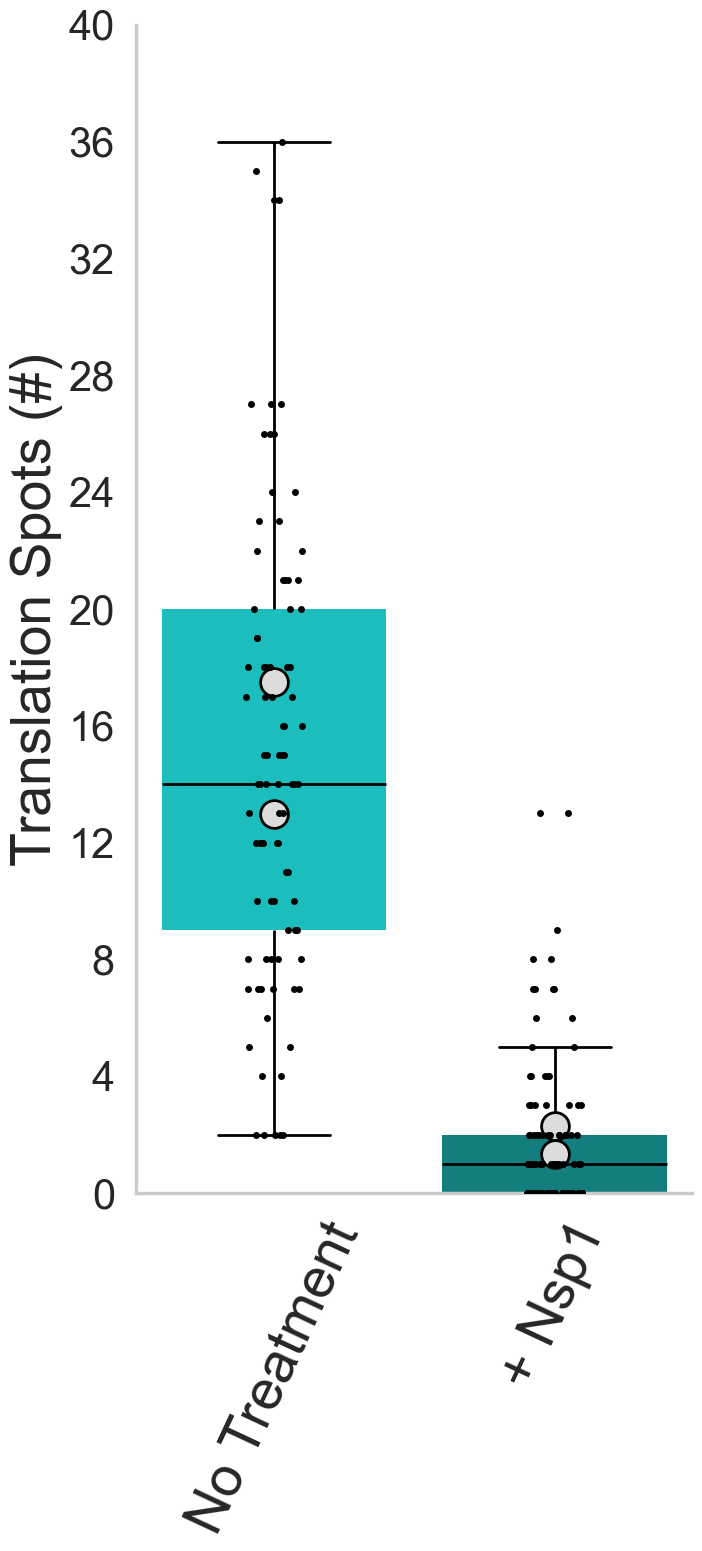

C:\Users\AdamC\AppData\Local\Temp\ipykernel_38628\3992199329.py:71: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Cyto mRNA", data=data, order=order, ax=ax2, palette= magenta_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)
C:\Users\AdamC\AppData\Local\Temp\ipykernel_38628\3992199329.py:71: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(x="Experimental Type", y="Cyto mRNA", data=data, order=order, ax=ax2, palette= magenta_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)


Across x (within hue):
[hue=Endogenous MyH9] Control vs Nsp1_GFP: n=92/112, p=1.67e-24, ****
     test_group                                   contrast       x0        x1  \
0  x|within_hue  [hue=Endogenous MyH9] Control vs Nsp1_GFP  Control  Nsp1_GFP   

              hue0             hue1  n0   n1        pvalue stars  
0  Endogenous MyH9  Endogenous MyH9  92  112  1.667218e-24  ****  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_38628\3992199329.py:102: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


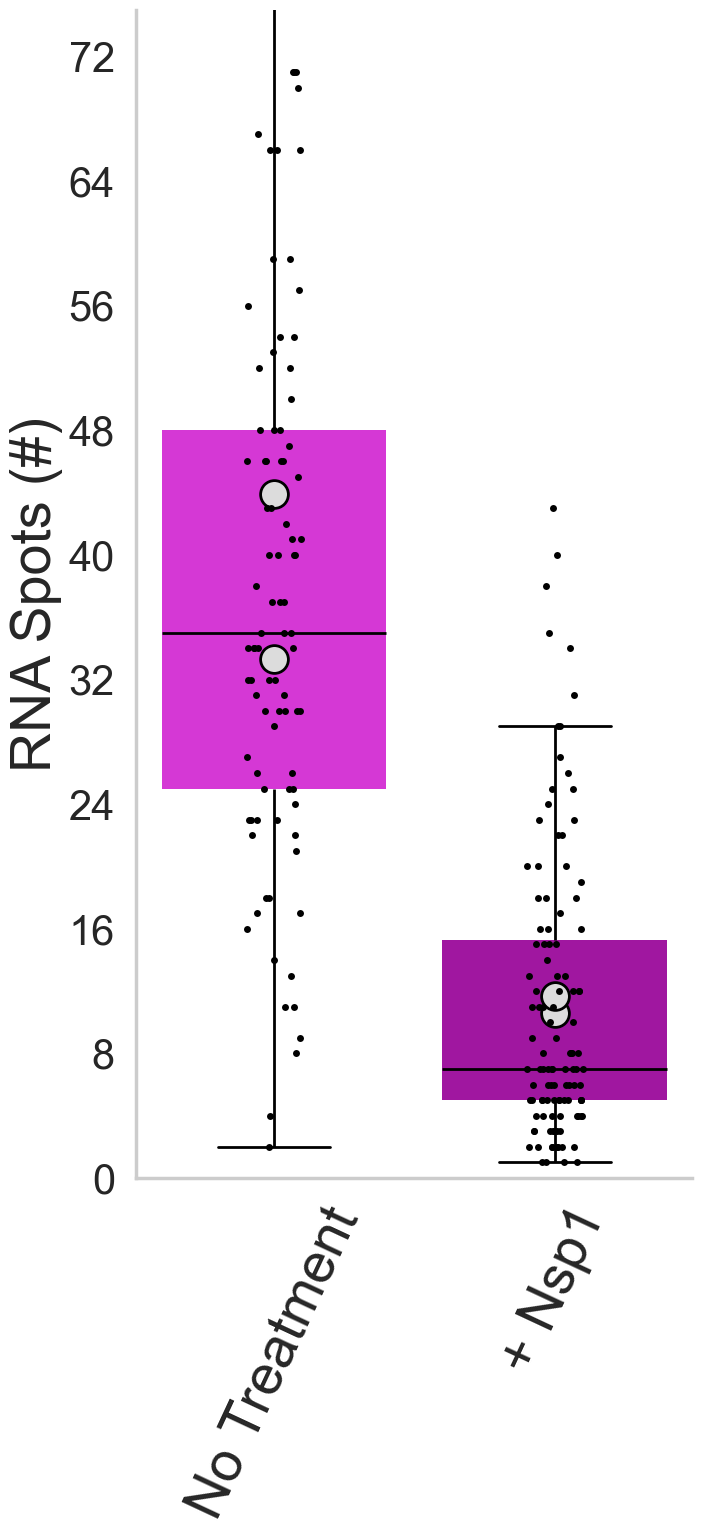

In [38]:
# Plot 1: Endogenous MyH9 with GFP plasmids
import os
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")
order = ["Control", "Nsp1_GFP"]

# Define the order for the x-axis categories
data = all_GFP_data[all_GFP_data["Experimental Type"].isin(["Control", "Nsp1_GFP"])]

superplot_translation = calculate_grouped_average(data, "Trnl Count", ["Experimental Group", "Experimental Type", "Date"])
superplot_rna = calculate_grouped_average(data, "Cyto mRNA", ["Experimental Group", "Experimental Type", "Date"])


# Define the x-tick labels
new_labels = ["No Treatment", "+ Nsp1"]


# Plot 1: Total Translation Spots
fig1, ax1 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Trnl Count", data=data, order=order, ax=ax1, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)


sns.stripplot(x="Experimental Type", y="Trnl Count", 
              data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax1, zorder=9)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Type", y="Super Trnl Count", hue="Experimental Group")



ax1.set_ylabel('Translation Spots (#)', fontsize=40)
ax1.set_ylim(0, 40)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.yaxis.set_major_locator(MaxNLocator(nbins=10))
ax1.set_xticklabels(new_labels, fontsize=40, rotation=65)

ax1.set_xlabel('')

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

res1 = print_ttest_summary( x="Experimental Type", y="Trnl Count", hue="Experimental Group",
            data=data, order=order)
print(res1)

# Save the figure for Total Translation Spots
filename_svg_translation = os.path.join(save_directory, "Total Translation Spots Host UTR.svg")
filename_png_translation = os.path.join(save_directory, "Total Translation Spots Host UTR.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Total Translation Spots
plt.tight_layout()
plt.show()



# Plot 2: Total RNA Spots
fig2, ax2 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Cyto mRNA", data=data, order=order, ax=ax2, palette= magenta_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)

sns.stripplot(x="Experimental Type", y="Cyto mRNA",
              data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax2, zorder=9)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Cyto mRNA", hue="Experimental Group")


ax2.set_ylabel('RNA Spots (#)', fontsize=40)
ax2.set_ylim(0, 75)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.yaxis.set_major_locator(MaxNLocator(nbins=10))
ax2.set_xticklabels(new_labels, fontsize=40, rotation=65)

ax2.set_xlabel('')

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res2 = print_ttest_summary( x="Experimental Type", y="Cyto mRNA", hue="Experimental Group",
            data=data, order=order)
print(res2)

# Save the figure for Total RNA Spots
filename_svg_rna = os.path.join(save_directory, "Endogenous GFP.svg")
filename_png_rna = os.path.join(save_directory, "Endogenous GFP.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for Total RNA Spots
plt.tight_layout()
plt.show()

C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\3648130300.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Trnl Count", data=data, order=order, ax=ax1, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)
C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\3648130300.py:28: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(x="Experimental Type", y="Trnl Count", data=data, order=order, ax=ax1, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)


Across x (within hue):
[hue=Endogenous MyH9] Control vs Nsp1_mCh: n=119/83, p=4.55e-33, ****
     test_group                                   contrast       x0        x1  \
0  x|within_hue  [hue=Endogenous MyH9] Control vs Nsp1_mCh  Control  Nsp1_mCh   

              hue0             hue1   n0  n1        pvalue stars  
0  Endogenous MyH9  Endogenous MyH9  119  83  4.553836e-33  ****  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\3648130300.py:61: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


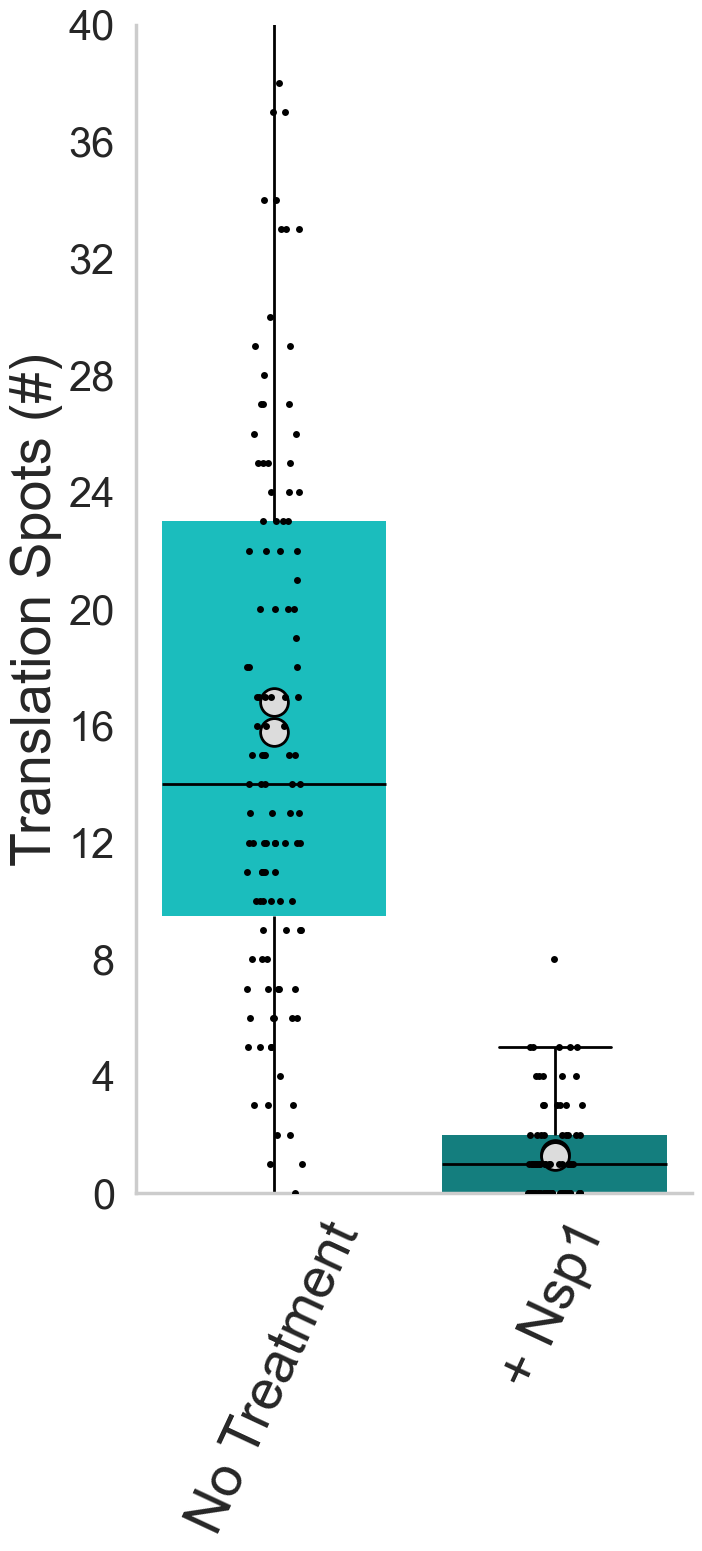

C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\3648130300.py:71: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Cyto mRNA", data=data, order=order, ax=ax2, palette= magenta_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)
C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\3648130300.py:71: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(x="Experimental Type", y="Cyto mRNA", data=data, order=order, ax=ax2, palette= magenta_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)


Across x (within hue):
[hue=Endogenous MyH9] Control vs Nsp1_mCh: n=119/83, p=8.81e-29, ****
     test_group                                   contrast       x0        x1  \
0  x|within_hue  [hue=Endogenous MyH9] Control vs Nsp1_mCh  Control  Nsp1_mCh   

              hue0             hue1   n0  n1        pvalue stars  
0  Endogenous MyH9  Endogenous MyH9  119  83  8.806253e-29  ****  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\3648130300.py:102: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


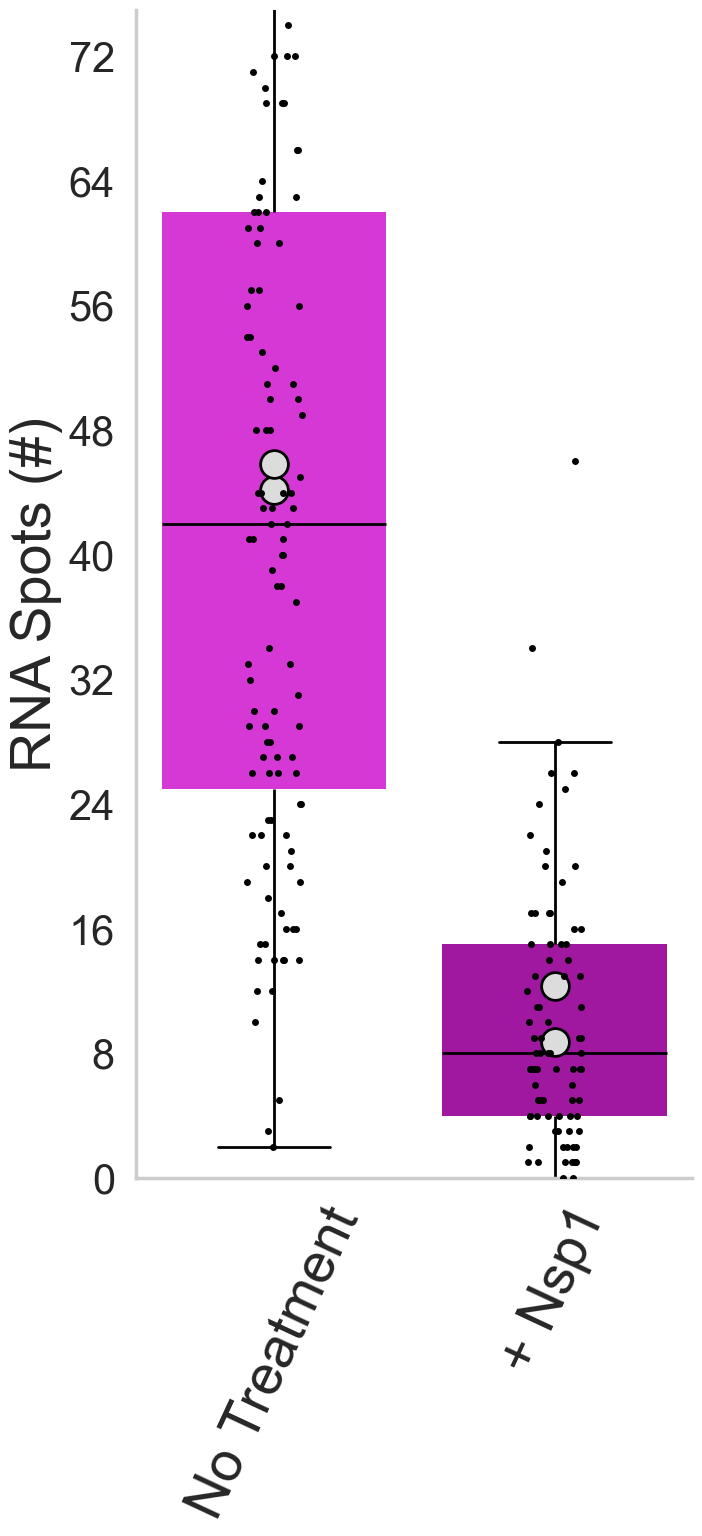

In [30]:
# Plot 2: Endogenous MyH9 with mCh plasmids
import os
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")
order = ["Control", "Nsp1_mCh"]

# Define the order for the x-axis categories
data = all_mCh_data[all_mCh_data["Experimental Type"].isin(["Control", "Nsp1_mCh"])]

superplot_translation = calculate_grouped_average(data, "Trnl Count", ["Experimental Group", "Experimental Type", "Date"])
superplot_rna = calculate_grouped_average(data, "Cyto mRNA", ["Experimental Group", "Experimental Type", "Date"])


# Define the x-tick labels
new_labels = ["No Treatment", "+ Nsp1"]


# Plot 1: Total Translation Spots
fig1, ax1 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Trnl Count", data=data, order=order, ax=ax1, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)


sns.stripplot(x="Experimental Type", y="Trnl Count", 
              data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax1, zorder=9)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Type", y="Super Trnl Count", hue="Experimental Group")



ax1.set_ylabel('Translation Spots (#)', fontsize=40)
ax1.set_ylim(0, 40)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.yaxis.set_major_locator(MaxNLocator(nbins=10))
ax1.set_xticklabels(new_labels, fontsize=40, rotation=65)

ax1.set_xlabel('')

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

res1 = print_ttest_summary( x="Experimental Type", y="Trnl Count", hue="Experimental Group",
            data=data, order=order)
print(res1)

# Save the figure for Total Translation Spots
filename_svg_translation = os.path.join(save_directory, "Total Translation Spots Host UTR.svg")
filename_png_translation = os.path.join(save_directory, "Total Translation Spots Host UTR.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Total Translation Spots
plt.tight_layout()
plt.show()



# Plot 2: Total RNA Spots
fig2, ax2 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Cyto mRNA", data=data, order=order, ax=ax2, palette= magenta_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)

sns.stripplot(x="Experimental Type", y="Cyto mRNA",
              data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax2, zorder=9)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Cyto mRNA", hue="Experimental Group")


ax2.set_ylabel('RNA Spots (#)', fontsize=40)
ax2.set_ylim(0, 75)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.yaxis.set_major_locator(MaxNLocator(nbins=10))
ax2.set_xticklabels(new_labels, fontsize=40, rotation=65)

ax2.set_xlabel('')

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res2 = print_ttest_summary( x="Experimental Type", y="Cyto mRNA", hue="Experimental Group",
            data=data, order=order)
print(res2)

# Save the figure for Total RNA Spots
filename_svg_rna = os.path.join(save_directory, "Endogenous mCh.svg")
filename_png_rna = os.path.join(save_directory, "Endogenous mCh.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for Total RNA Spots
plt.tight_layout()
plt.show()

C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\2802233809.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Trnl Count", data=data, order=order, ax=ax1, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)
C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\2802233809.py:28: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(x="Experimental Type", y="Trnl Count", data=data, order=order, ax=ax1, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)


Across x (within hue):
[hue=Endogenous MyH9] Control vs Nsp1: n=203/183, p=8.77e-62, ****
     test_group                               contrast       x0    x1  \
0  x|within_hue  [hue=Endogenous MyH9] Control vs Nsp1  Control  Nsp1   

              hue0             hue1   n0   n1        pvalue stars  
0  Endogenous MyH9  Endogenous MyH9  203  183  8.771370e-62  ****  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\2802233809.py:61: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


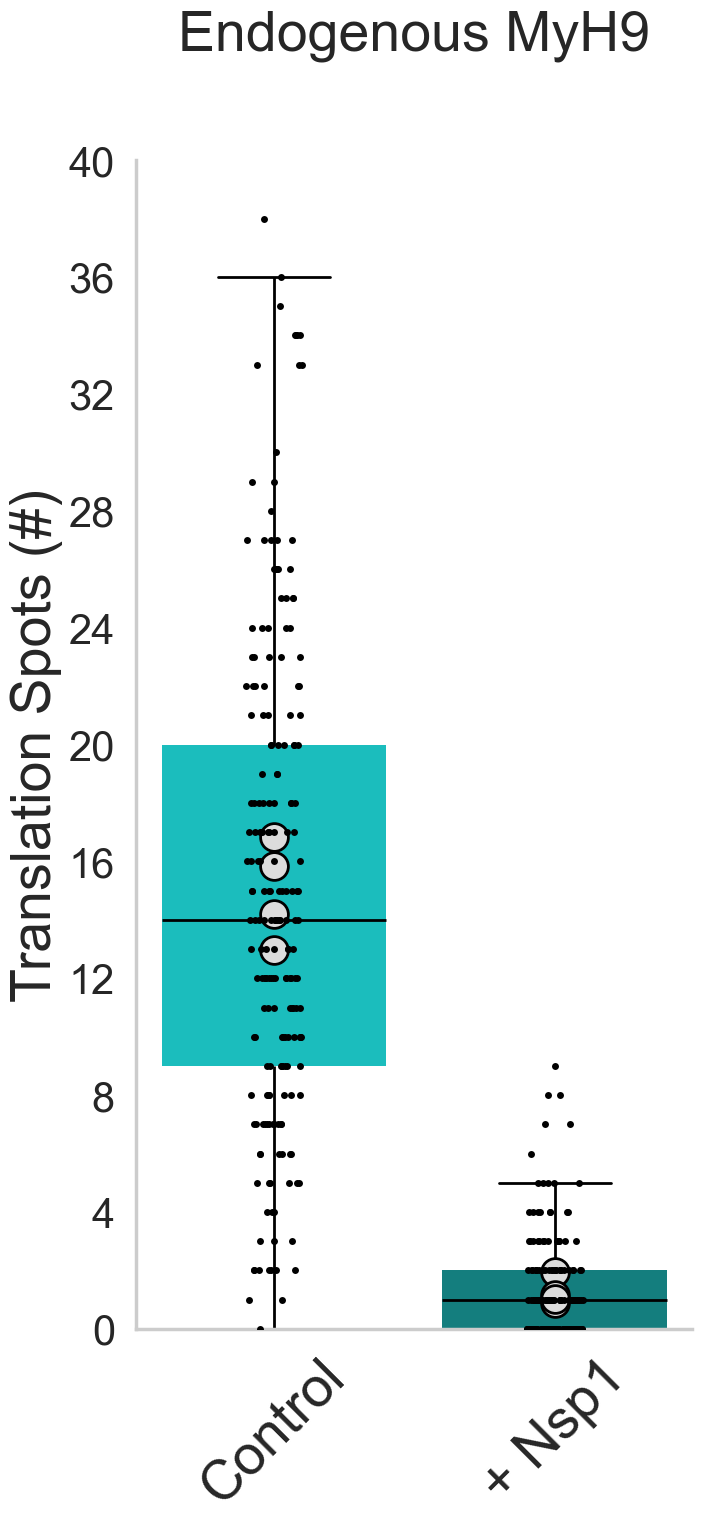

C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\2802233809.py:71: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Cyto mRNA", data=data, order=order, ax=ax2, palette= magenta_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)
C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\2802233809.py:71: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(x="Experimental Type", y="Cyto mRNA", data=data, order=order, ax=ax2, palette= magenta_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)


Across x (within hue):
[hue=Endogenous MyH9] Control vs Nsp1: n=203/183, p=2.04e-54, ****
     test_group                               contrast       x0    x1  \
0  x|within_hue  [hue=Endogenous MyH9] Control vs Nsp1  Control  Nsp1   

              hue0             hue1   n0   n1        pvalue stars  
0  Endogenous MyH9  Endogenous MyH9  203  183  2.039070e-54  ****  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\2802233809.py:102: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


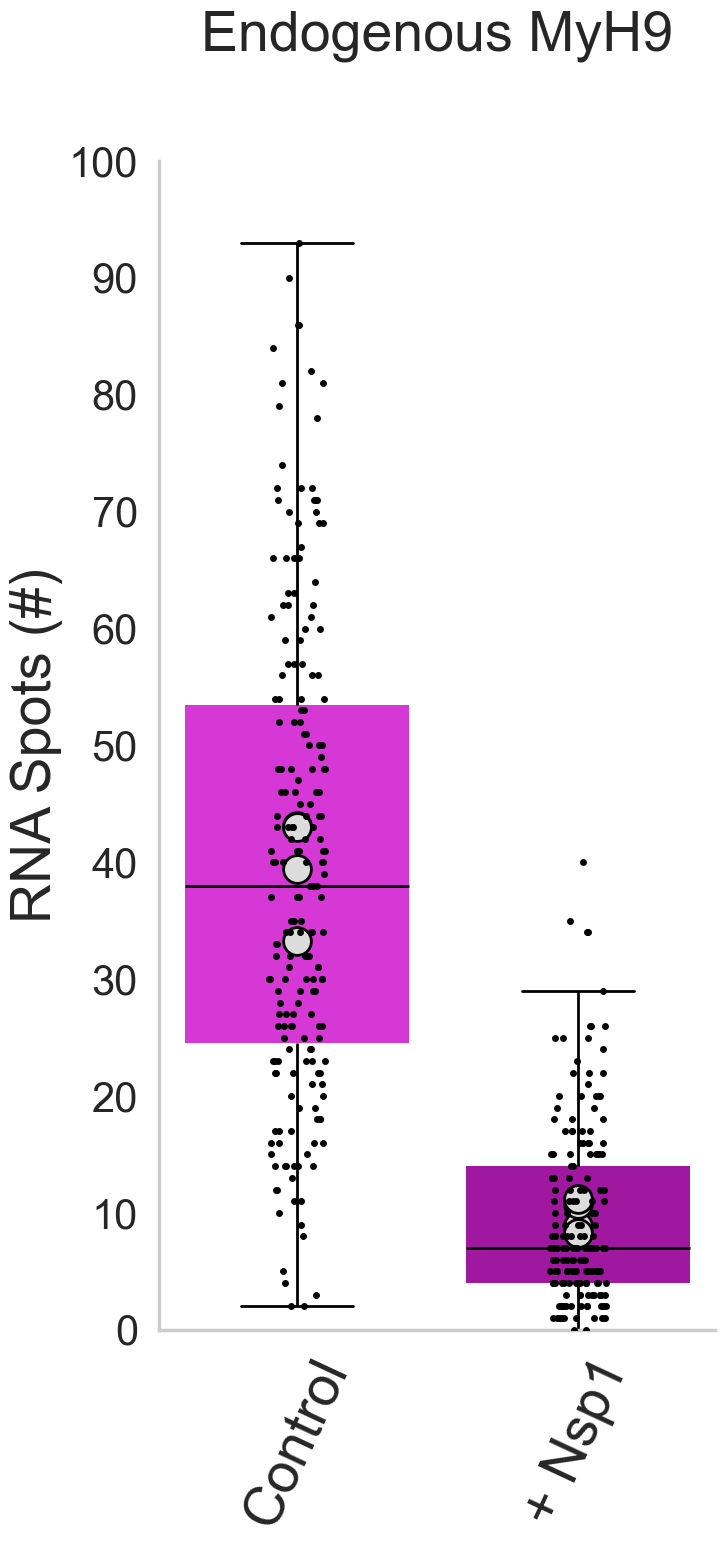

In [31]:
# Plot 3: Cyto Endogenous MyH9 with combined results
import os
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")
order = ["Control", "Nsp1"]

# Define the order for the x-axis categories
data = df_no_outliers

superplot_translation = calculate_grouped_average(data, "Trnl Count", ["Experimental Group", "Experimental Type", "Date"])
superplot_rna = calculate_grouped_average(data, "Cyto mRNA", ["Experimental Group", "Experimental Type", "Date"])


# Define the x-tick labels
new_labels = ["Control", "+ Nsp1"]


# Plot 1: Total Translation Spots
fig1, ax1 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Trnl Count", data=data, order=order, ax=ax1, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)


sns.stripplot(x="Experimental Type", y="Trnl Count", 
              data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax1, zorder=9)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Type", y="Super Trnl Count", hue="Experimental Group")


ax1.set_title("Endogenous MyH9", fontsize=40, pad=80)
ax1.set_ylabel('Translation Spots (#)', fontsize=40)
ax1.set_ylim(0, 40)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.yaxis.set_major_locator(MaxNLocator(nbins=10))
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax1.set_xlabel('')

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

res1 = print_ttest_summary( x="Experimental Type", y="Trnl Count", hue="Experimental Group",
            data=data, order=order)
print(res1)

# Save the figure for Total Translation Spots
filename_svg_translation = os.path.join(save_directory + endogenous_folder, "Total Translation Spots Cyto Endogenous MyH9.svg")
filename_png_translation = os.path.join(save_directory + endogenous_folder, "Total Translation Spots Cyto Endogenous MyH9.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Total Translation Spots
plt.tight_layout()
plt.show()



# Plot 2: Total RNA Spots
fig2, ax2 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Cyto mRNA", data=data, order=order, ax=ax2, palette= magenta_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)

sns.stripplot(x="Experimental Type", y="Cyto mRNA",
              data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax2, zorder=9)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Cyto mRNA", hue="Experimental Group")

ax2.set_title("Endogenous MyH9", fontsize=40, pad=80)
ax2.set_ylabel('RNA Spots (#)', fontsize=40)
ax2.set_ylim(0, 100)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.yaxis.set_major_locator(MaxNLocator(nbins=10))
ax2.set_xticklabels(new_labels, fontsize=40, rotation=65)

ax2.set_xlabel('')

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res2 = print_ttest_summary( x="Experimental Type", y="Cyto mRNA", hue="Experimental Group",
            data=data, order=order)
print(res2)

# Save the figure for Total RNA Spots
filename_svg_rna = os.path.join(save_directory + endogenous_folder, "Total RNA Spots Cyto Endogenous MyH9.svg")
filename_png_rna = os.path.join(save_directory + endogenous_folder, "Total RNA Spots Cyto Endogenous MyH9.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for Total RNA Spots
plt.tight_layout()
plt.show()

C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\3791374720.py:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Experimental Type", y="Trnl Count (scaled)",
C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\3791374720.py:49: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.barplot(x="Experimental Type", y="Trnl Count (scaled)",


Across x (within hue):
[hue=Endogenous MyH9] Control vs Nsp1: n=202/183, p=2.11e-62, ****
     test_group                               contrast       x0    x1  \
0  x|within_hue  [hue=Endogenous MyH9] Control vs Nsp1  Control  Nsp1   

              hue0             hue1   n0   n1        pvalue stars  
0  Endogenous MyH9  Endogenous MyH9  202  183  2.114474e-62  ****  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\3791374720.py:89: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


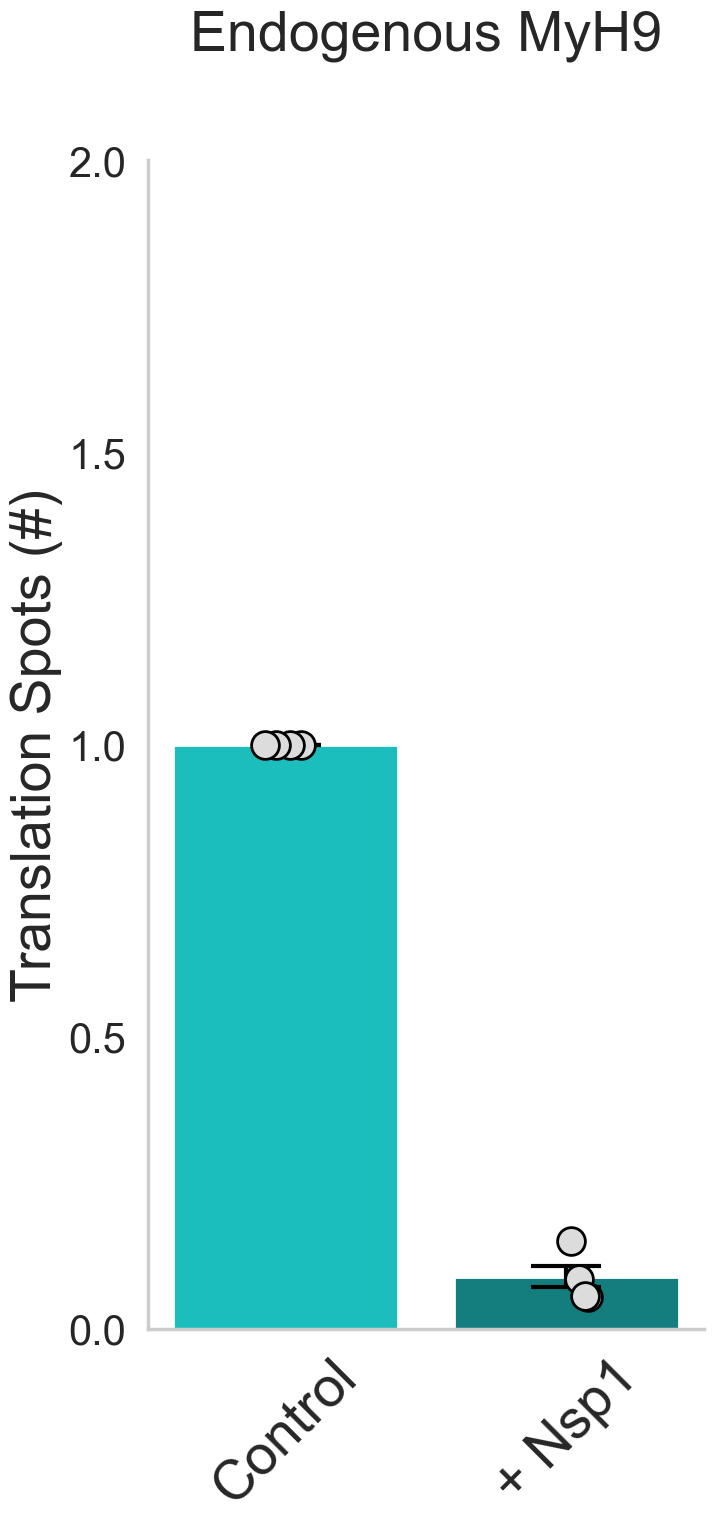

C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\3791374720.py:110: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Experimental Type", y="Cyto mRNA (scaled)",
C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\3791374720.py:110: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.barplot(x="Experimental Type", y="Cyto mRNA (scaled)",


Across x (within hue):
[hue=Endogenous MyH9] Control vs Nsp1: n=202/183, p=3.29e-54, ****
     test_group                               contrast       x0    x1  \
0  x|within_hue  [hue=Endogenous MyH9] Control vs Nsp1  Control  Nsp1   

              hue0             hue1   n0   n1        pvalue stars  
0  Endogenous MyH9  Endogenous MyH9  202  183  3.285090e-54  ****  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\3791374720.py:151: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


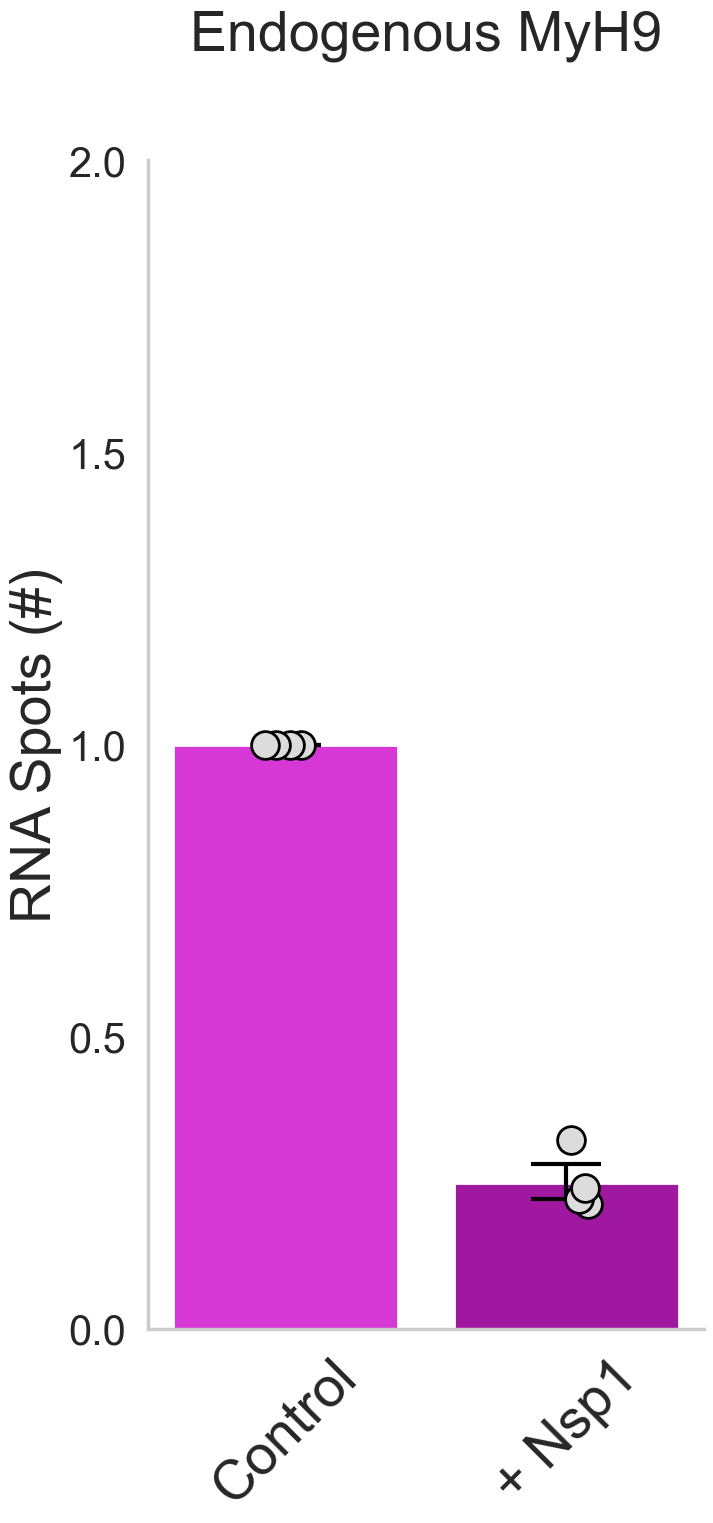

In [32]:
# Plot 3b: Scaled Endogenous Translation Spots and Cyto mRNA
import os
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")
order = ["Control", "Nsp1"]

# Define the order for the x-axis categories
data = df_no_outliers_total


data = scale_by_reference(
    df=data[data["Experimental Group"] == "Endogenous MyH9"],
    value_cols=("Trnl Count", "Cyto mRNA"),
    ref_group="Endogenous MyH9",
    ref_type="Control",
)

col = "Trnl Count (scaled)"
ref_type = "Control"

means, yerr, cats, stats = seaborn_like_bar_stats(
    data=data,
    col=col,
    category_col="Experimental Type",
    order=order,
    ref_type=ref_type,
    n_boot=1000,   # or 20_000 for extra stability
    ci=95,
)

superplot_translation = calculate_grouped_average(data, "Trnl Count (scaled)", ["Experimental Group", "Experimental Type", "Replicate Number"])
superplot_rna = calculate_grouped_average(data, "Cyto mRNA (scaled)", ["Experimental Group", "Experimental Type", "Replicate Number"])


# Define the x-tick labels
new_labels = ["Control", "+ Nsp1"]


# Plot 1: Trnl Count
fig1, ax1 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.barplot(x="Experimental Type", y="Trnl Count (scaled)", 
            data=data, order=order, ax=ax1, palette= blue_palette, errorbar=None)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Type", y="Super Trnl Count (scaled)", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)

# Manual asymmetric CI (reference gets 0 height)
xpos = np.arange(len(cats))
ax1.errorbar(
    xpos, means, yerr=yerr,
    fmt="none",
    elinewidth=3,
    capsize=25,
    capthick=3,
    color="black",
    alpha=1,
)
ax1.set_title("Endogenous MyH9", fontsize=40, pad=80)
ax1.set_ylabel('Translation Spots (#)', fontsize=40)
ax1.set_ylim(0, 2)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.yaxis.set_major_locator(MaxNLocator(nbins=4))
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax1.set_xlabel('')

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

res1 = print_ttest_summary( x="Experimental Type", y="Trnl Count (scaled)", hue="Experimental Group",
            data=data, order=order)
print(res1)

# Save the figure for Trnl Count
filename_svg_translation = os.path.join(save_directory + endogenous_folder, "Normalized Cyto Trnl Count Endogenous.svg")
filename_png_translation = os.path.join(save_directory + endogenous_folder, "Normalized Cyto Trnl Count Endogenous.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Trnl Count
plt.tight_layout()
plt.show()

col = "Cyto mRNA (scaled)"
ref_type = "Control"

means, yerr, cats, stats = seaborn_like_bar_stats(
    data=data,
    col=col,
    category_col="Experimental Type",
    order=order,
    ref_type=ref_type,
    n_boot=1000,   # or 20_000 for extra stability
    ci=95,
)

# Plot 2: Total mRNA
fig2, ax2 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.barplot(x="Experimental Type", y="Cyto mRNA (scaled)", 
            data=data, order=order, ax=ax2, palette= magenta_palette, errorbar=None)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Cyto mRNA (scaled)", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)

# Manual asymmetric CI (reference gets 0 height)
xpos = np.arange(len(cats))
ax2.errorbar(
    xpos, means, yerr=yerr,
    fmt="none",
    elinewidth=3,
    capsize=25,
    capthick=3,
    color="black",
    alpha=1,
)

ax2.set_title("Endogenous MyH9", fontsize=40, pad=80)
ax2.set_ylabel('RNA Spots (#)', fontsize=40)
ax2.set_ylim(0, 2)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.yaxis.set_major_locator(MaxNLocator(nbins=4))
ax2.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax2.set_xlabel('')

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res2 = print_ttest_summary( x="Experimental Type", y="Cyto mRNA (scaled)", hue="Experimental Group",
            data=data, order=order)
print(res2)

# Save the figure for Total mRNA
filename_svg_rna = os.path.join(save_directory + endogenous_folder, "Normalized Cyto mRNA Endogenous.svg")
filename_png_rna = os.path.join(save_directory + endogenous_folder, "Normalized Cyto mRNA Endogenous.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for Total mRNA
plt.tight_layout()
plt.show()

C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\321338476.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Trnl Count", data=data, order=order, ax=ax1, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)
C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\321338476.py:28: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(x="Experimental Type", y="Trnl Count", data=data, order=order, ax=ax1, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)


Across x (within hue):
[hue=Endogenous MyH9] Control vs Nsp1: n=202/183, p=1.1e-61, ****
     test_group                               contrast       x0    x1  \
0  x|within_hue  [hue=Endogenous MyH9] Control vs Nsp1  Control  Nsp1   

              hue0             hue1   n0   n1        pvalue stars  
0  Endogenous MyH9  Endogenous MyH9  202  183  1.097000e-61  ****  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\321338476.py:61: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


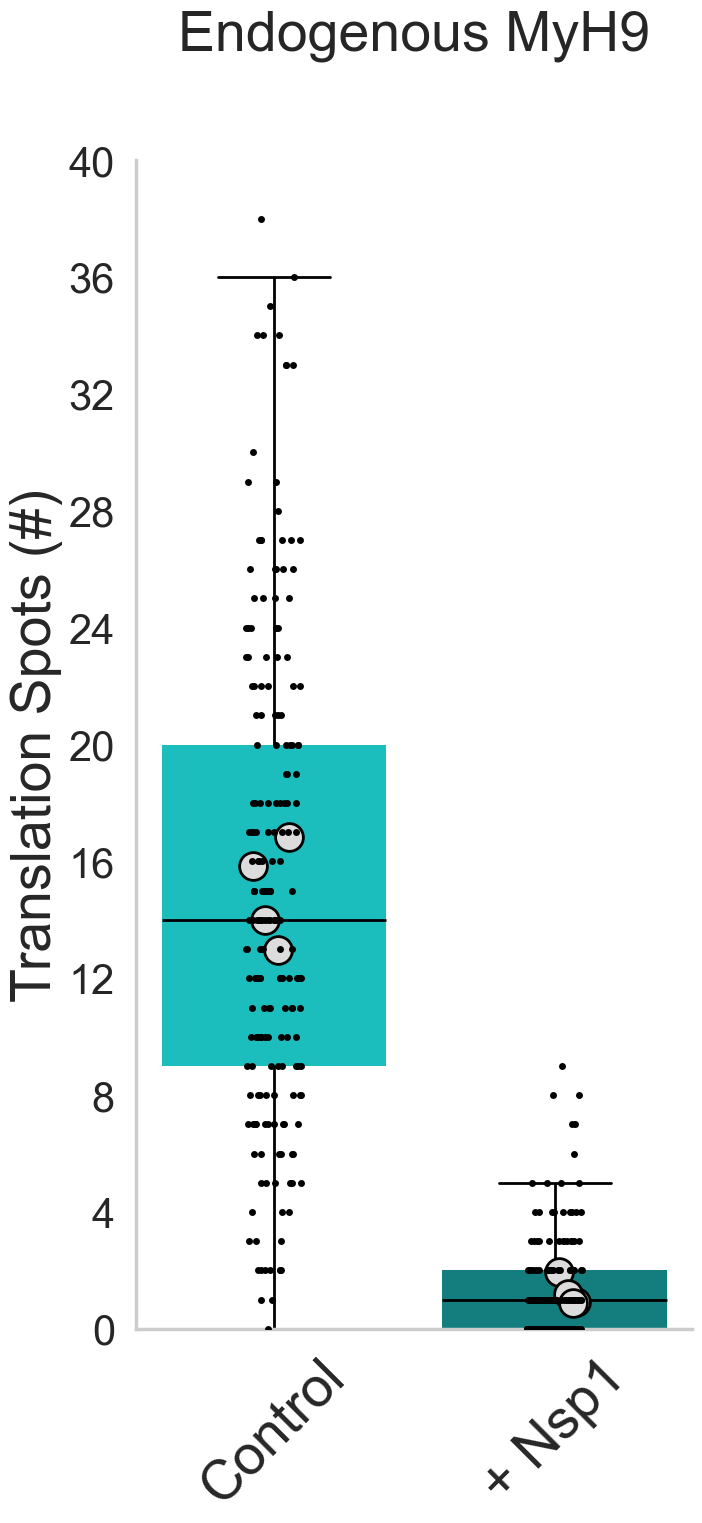

C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\321338476.py:71: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Total mRNA", data=data, order=order, ax=ax2, palette= magenta_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)
C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\321338476.py:71: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(x="Experimental Type", y="Total mRNA", data=data, order=order, ax=ax2, palette= magenta_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)


Across x (within hue):
[hue=Endogenous MyH9] Control vs Nsp1: n=202/183, p=1.5e-39, ****
     test_group                               contrast       x0    x1  \
0  x|within_hue  [hue=Endogenous MyH9] Control vs Nsp1  Control  Nsp1   

              hue0             hue1   n0   n1        pvalue stars  
0  Endogenous MyH9  Endogenous MyH9  202  183  1.504204e-39  ****  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\321338476.py:102: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


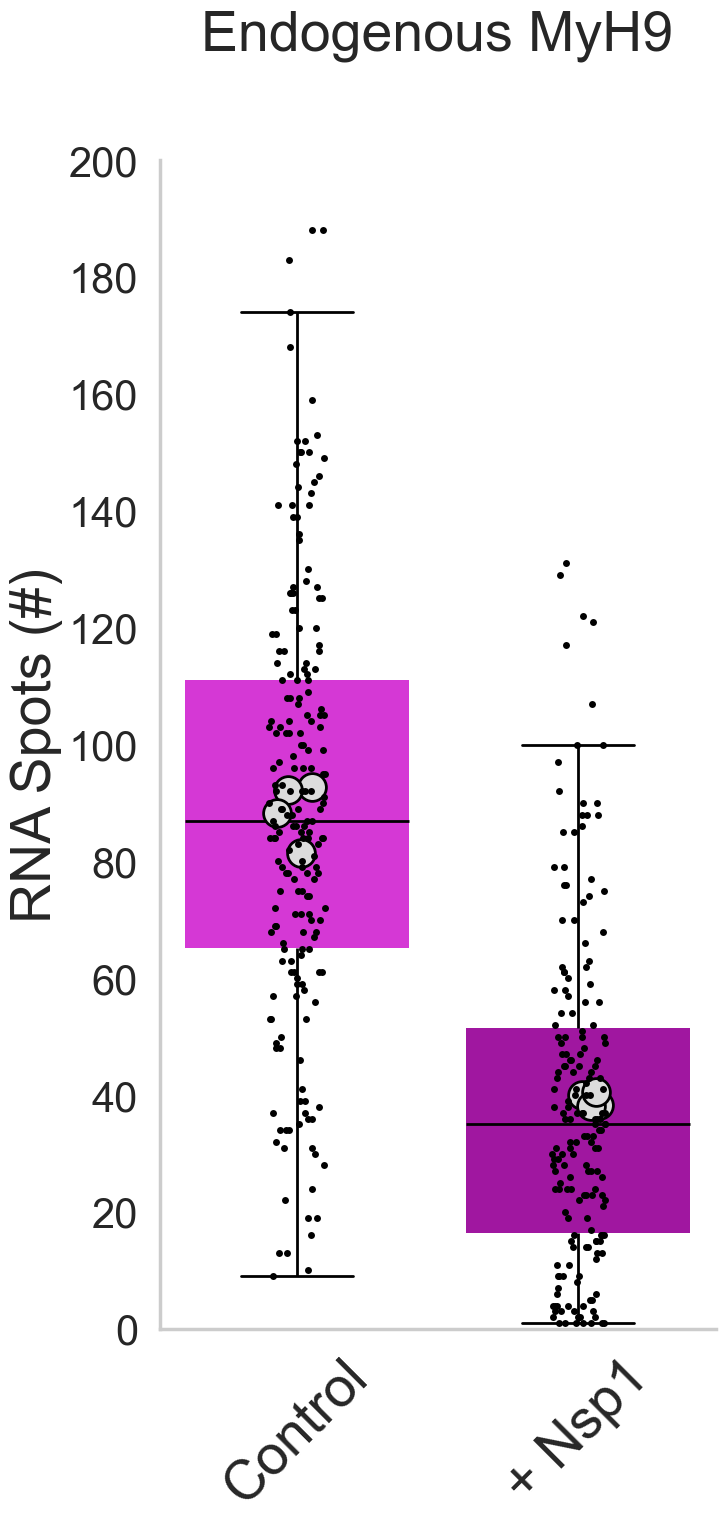

In [33]:
# Plot 4: Endogenous MyH9 totals with combined results
import os
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")
order = ["Control", "Nsp1"]

# Define the order for the x-axis categories
data = df_no_outliers_total

superplot_translation = calculate_grouped_average(data, "Trnl Count", ["Experimental Group", "Experimental Type", "Replicate Number"])
superplot_rna = calculate_grouped_average(data, "Total mRNA", ["Experimental Group", "Experimental Type", "Replicate Number"])


# Define the x-tick labels
new_labels = ["Control", "+ Nsp1"]


# Plot 1: Total Translation Spots
fig1, ax1 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Trnl Count", data=data, order=order, ax=ax1, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)


sns.stripplot(x="Experimental Type", y="Trnl Count", 
              data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax1, zorder=9)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Type", y="Super Trnl Count", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)


ax1.set_title("Endogenous MyH9", fontsize=40, pad=80)
ax1.set_ylabel('Translation Spots (#)', fontsize=40)
ax1.set_ylim(0, 40)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.yaxis.set_major_locator(MaxNLocator(nbins=10))
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax1.set_xlabel('')

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

res1 = print_ttest_summary( x="Experimental Type", y="Trnl Count", hue="Experimental Group",
            data=data, order=order)
print(res1)

# Save the figure for Total Translation Spots
filename_svg_translation = os.path.join(save_directory + endogenous_folder, "Total Translation Spots Endogenous MyH9.svg")
filename_png_translation = os.path.join(save_directory + endogenous_folder, "Total Translation Spots Endogenous MyH9.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Total Translation Spots
plt.tight_layout()
plt.show()



# Plot 2: Total RNA Spots
fig2, ax2 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.boxplot(x="Experimental Type", y="Total mRNA", data=data, order=order, ax=ax2, palette= magenta_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2),fliersize=0)

sns.stripplot(x="Experimental Type", y="Total mRNA",
              data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax2, zorder=9)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Total mRNA", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)

ax2.set_title("Endogenous MyH9", fontsize=40, pad=80)
ax2.set_ylabel('RNA Spots (#)', fontsize=40)
ax2.set_ylim(0, 200)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.yaxis.set_major_locator(MaxNLocator(nbins=10))
ax2.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax2.set_xlabel('')

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res2 = print_ttest_summary( x="Experimental Type", y="Total mRNA", hue="Experimental Group",
            data=data, order=order)
print(res2)

# Save the figure for Total RNA Spots
filename_svg_rna = os.path.join(save_directory + endogenous_folder, "Total RNA Spots Endogenous MyH9.svg")
filename_png_rna = os.path.join(save_directory + endogenous_folder, "Total RNA Spots Endogenous MyH9.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for Total RNA Spots
plt.tight_layout()
plt.show()

C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\1785401947.py:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Experimental Type", y="Trnl Count (scaled)",
C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\1785401947.py:49: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.barplot(x="Experimental Type", y="Trnl Count (scaled)",


Across x (within hue):
[hue=Endogenous MyH9] Control vs Nsp1: n=202/183, p=2.11e-62, ****
     test_group                               contrast       x0    x1  \
0  x|within_hue  [hue=Endogenous MyH9] Control vs Nsp1  Control  Nsp1   

              hue0             hue1   n0   n1        pvalue stars  
0  Endogenous MyH9  Endogenous MyH9  202  183  2.114474e-62  ****  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\1785401947.py:89: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


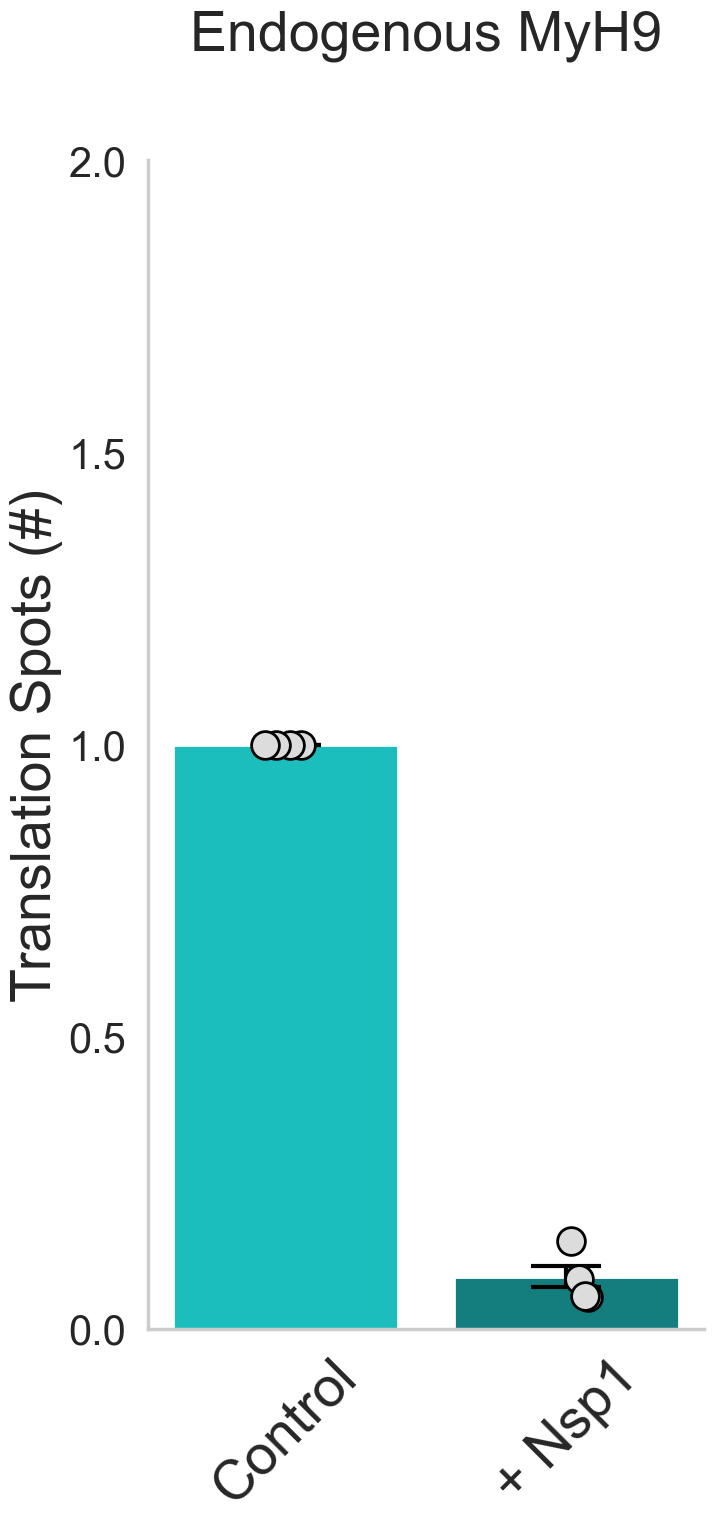

C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\1785401947.py:110: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Experimental Type", y="Total mRNA (scaled)",
C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\1785401947.py:110: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.barplot(x="Experimental Type", y="Total mRNA (scaled)",


Across x (within hue):
[hue=Endogenous MyH9] Control vs Nsp1: n=202/183, p=4.97e-40, ****
     test_group                               contrast       x0    x1  \
0  x|within_hue  [hue=Endogenous MyH9] Control vs Nsp1  Control  Nsp1   

              hue0             hue1   n0   n1        pvalue stars  
0  Endogenous MyH9  Endogenous MyH9  202  183  4.971111e-40  ****  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\1785401947.py:151: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


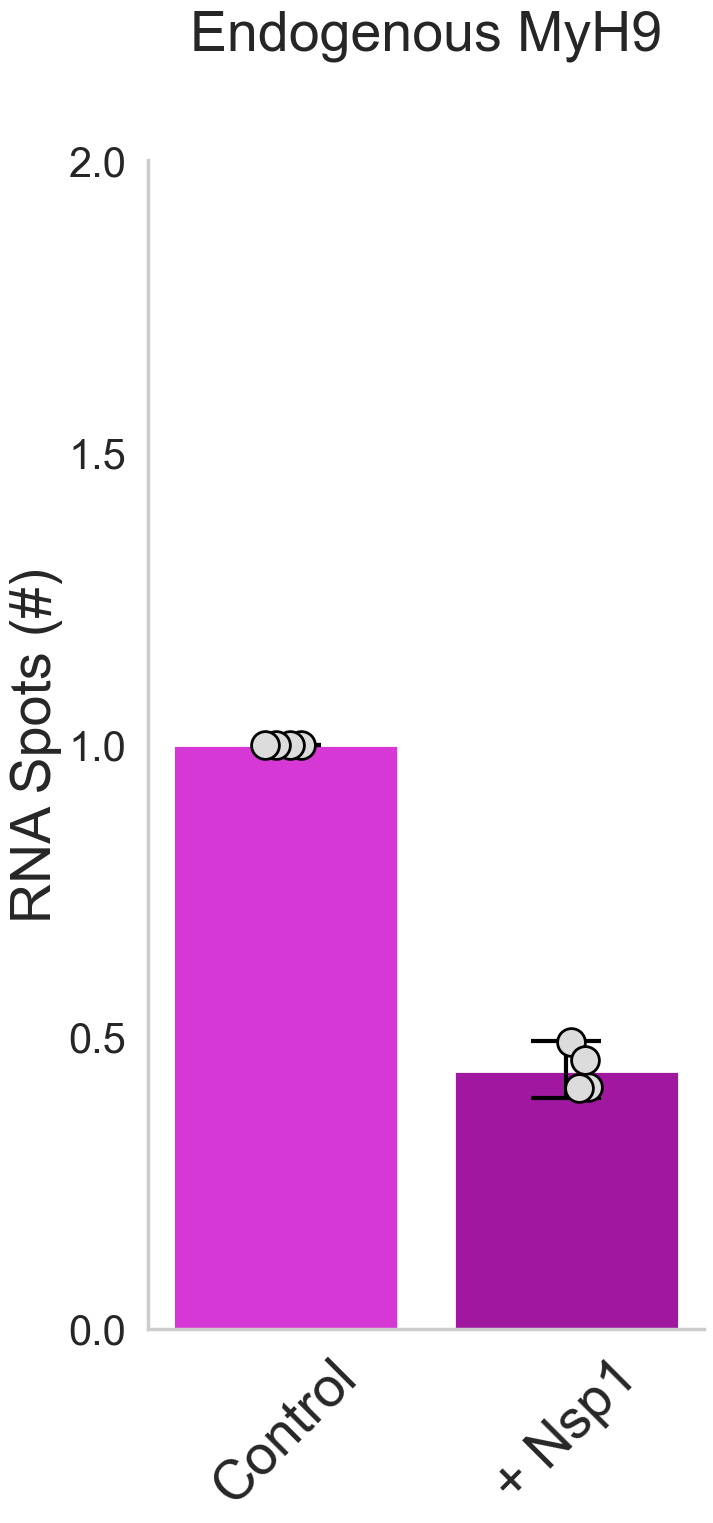

In [34]:
# Plot 4b: Scaled Endogenous Translation Spots and Total mRNA
import os
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")
order = ["Control", "Nsp1"]

# Define the order for the x-axis categories
data = df_no_outliers_total


data = scale_by_reference(
    df=data[data["Experimental Group"] == "Endogenous MyH9"],
    value_cols=("Trnl Count", "Total mRNA"),
    ref_group="Endogenous MyH9",
    ref_type="Control",
)

col = "Trnl Count (scaled)"
ref_type = "Control"

means, yerr, cats, stats = seaborn_like_bar_stats(
    data=data,
    col=col,
    category_col="Experimental Type",
    order=order,
    ref_type=ref_type,
    n_boot=1000,   # or 20_000 for extra stability
    ci=95,
)

superplot_translation = calculate_grouped_average(data, "Trnl Count (scaled)", ["Experimental Group", "Experimental Type", "Replicate Number"])
superplot_rna = calculate_grouped_average(data, "Total mRNA (scaled)", ["Experimental Group", "Experimental Type", "Replicate Number"])


# Define the x-tick labels
new_labels = ["Control", "+ Nsp1"]


# Plot 1: Trnl Count
fig1, ax1 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.barplot(x="Experimental Type", y="Trnl Count (scaled)", 
            data=data, order=order, ax=ax1, palette= blue_palette, errorbar=None)

plot_open_circles_with_hue(ax1, superplot_translation, order=order, x="Experimental Type", y="Super Trnl Count (scaled)", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)

# Manual asymmetric CI (reference gets 0 height)
xpos = np.arange(len(cats))
ax1.errorbar(
    xpos, means, yerr=yerr,
    fmt="none",
    elinewidth=3,
    capsize=25,
    capthick=3,
    color="black",
    alpha=1,
)
ax1.set_title("Endogenous MyH9", fontsize=40, pad=80)
ax1.set_ylabel('Translation Spots (#)', fontsize=40)
ax1.set_ylim(0, 2)
ax1.tick_params(axis='both', which='major', labelsize=30)
ax1.yaxis.set_major_locator(MaxNLocator(nbins=4))
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax1.set_xlabel('')

# Remove the extra legend
handles, labels = ax1.get_legend_handles_labels()
ax1.legend().remove()

res1 = print_ttest_summary( x="Experimental Type", y="Trnl Count (scaled)", hue="Experimental Group",
            data=data, order=order)
print(res1)

# Save the figure for Trnl Count
filename_svg_translation = os.path.join(save_directory + endogenous_folder, "Normalized Trnl Count Endogenous.svg")
filename_png_translation = os.path.join(save_directory + endogenous_folder, "Normalized Trnl Count Endogenous.png")
fig1.savefig(filename_svg_translation, format='svg', dpi = 300)
fig1.savefig(filename_png_translation, format='png', dpi = 300)

# Show the plot for Trnl Count
plt.tight_layout()
plt.show()

col = "Total mRNA (scaled)"
ref_type = "Control"

means, yerr, cats, stats = seaborn_like_bar_stats(
    data=data,
    col=col,
    category_col="Experimental Type",
    order=order,
    ref_type=ref_type,
    n_boot=1000,   # or 20_000 for extra stability
    ci=95,
)

# Plot 2: Total mRNA
fig2, ax2 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.barplot(x="Experimental Type", y="Total mRNA (scaled)", 
            data=data, order=order, ax=ax2, palette= magenta_palette, errorbar=None)

plot_open_circles_with_hue(ax2, superplot_rna, order=order, x="Experimental Type", y="Super Total mRNA (scaled)", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)

# Manual asymmetric CI (reference gets 0 height)
xpos = np.arange(len(cats))
ax2.errorbar(
    xpos, means, yerr=yerr,
    fmt="none",
    elinewidth=3,
    capsize=25,
    capthick=3,
    color="black",
    alpha=1,
)

ax2.set_title("Endogenous MyH9", fontsize=40, pad=80)
ax2.set_ylabel('RNA Spots (#)', fontsize=40)
ax2.set_ylim(0, 2)
ax2.tick_params(axis='both', which='major', labelsize=30)
ax2.yaxis.set_major_locator(MaxNLocator(nbins=4))
ax2.set_xticklabels(new_labels, fontsize=40, rotation=45)

ax2.set_xlabel('')

# Remove the extra legend
handles, labels = ax2.get_legend_handles_labels()
ax2.legend().remove()

res2 = print_ttest_summary( x="Experimental Type", y="Total mRNA (scaled)", hue="Experimental Group",
            data=data, order=order)
print(res2)

# Save the figure for Total mRNA
filename_svg_rna = os.path.join(save_directory + endogenous_folder, "Normalized Total mRNA Endogenous.svg")
filename_png_rna = os.path.join(save_directory + endogenous_folder, "Normalized Total mRNA Endogenous.png")
fig2.savefig(filename_svg_rna, format='svg', dpi = 300)
fig2.savefig(filename_png_rna, format='png', dpi = 300)

# Show the plot for Total mRNA
plt.tight_layout()
plt.show()

C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\3646312677.py:89: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\3646312677.py:89: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.barplot(


Across x (within hue):
[hue=Endogenous MyH9] Control vs Nsp1: n=202/183, p=2.11e-62, ****
     test_group                               contrast       x0    x1  \
0  x|within_hue  [hue=Endogenous MyH9] Control vs Nsp1  Control  Nsp1   

              hue0             hue1   n0   n1        pvalue stars  
0  Endogenous MyH9  Endogenous MyH9  202  183  2.114474e-62  ****  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\3646312677.py:167: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


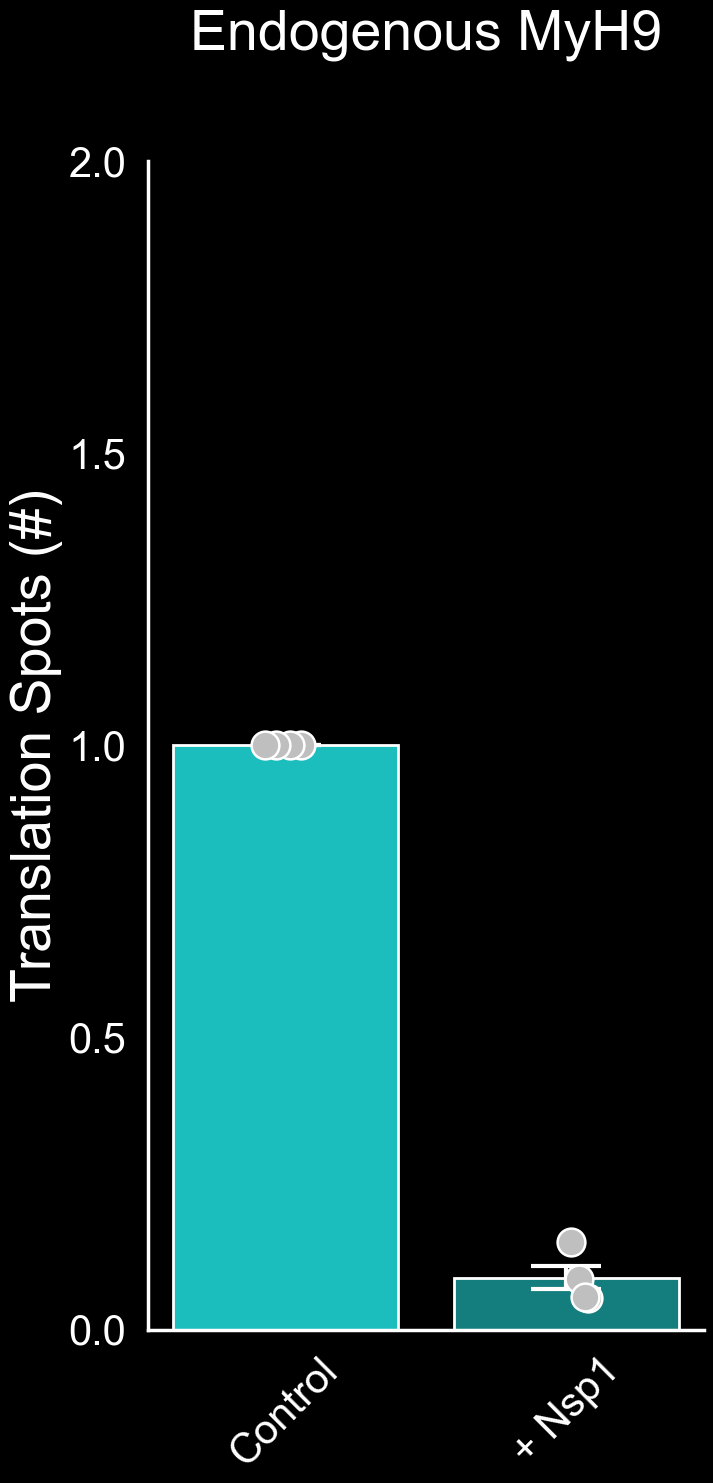

C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\3646312677.py:190: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\3646312677.py:190: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.barplot(


Across x (within hue):
[hue=Endogenous MyH9] Control vs Nsp1: n=202/183, p=4.97e-40, ****
     test_group                               contrast       x0    x1  \
0  x|within_hue  [hue=Endogenous MyH9] Control vs Nsp1  Control  Nsp1   

              hue0             hue1   n0   n1        pvalue stars  
0  Endogenous MyH9  Endogenous MyH9  202  183  4.971111e-40  ****  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\3646312677.py:268: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


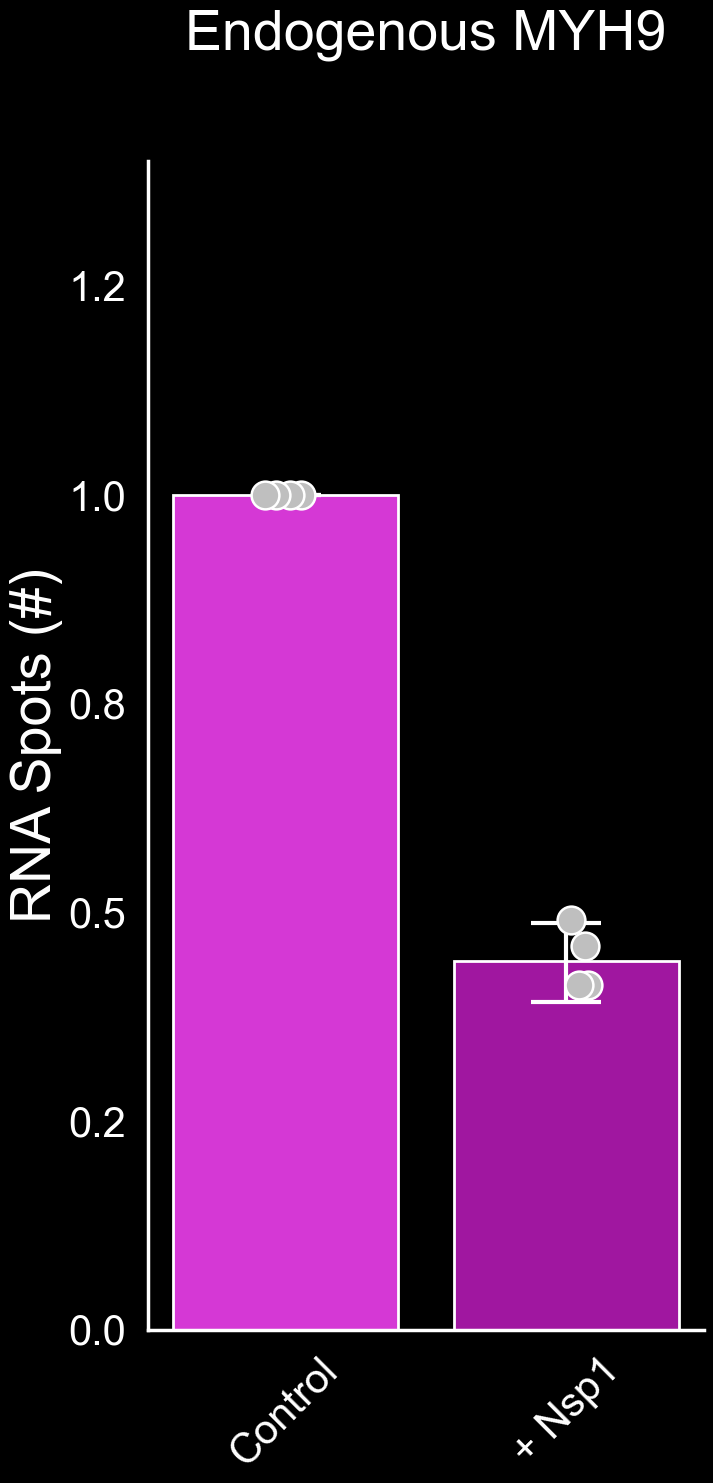

In [39]:
# Plot 4c: Scaled Endogenous Translation Spots and Total mRNA
import os
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.collections as mcoll
from matplotlib.ticker import MaxNLocator, FormatStrFormatter

# Set the style and font scale
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

order = ["Control", "Nsp1"]
new_labels = ["Control", "+ Nsp1"]

# Save folder
output_folder = r"Z:\koch\Presentations and Figures\Figures\Endogenous Plots\Black Background"
os.makedirs(output_folder, exist_ok=True)

def apply_black_background(ax, fig):
    fig.patch.set_facecolor("black")
    ax.set_facecolor("black")

    ax.tick_params(axis='both', which='major', colors='white', labelsize=30)
    ax.xaxis.label.set_color("white")
    ax.yaxis.label.set_color("white")
    ax.title.set_color("white")

    for spine in ax.spines.values():
        spine.set_color("white")

    for tick in ax.xaxis.get_ticklines() + ax.yaxis.get_ticklines():
        tick.set_color("white")

    # Keep superplot circles gray-filled with white edge
    for coll in ax.collections:
        if isinstance(coll, mcoll.PathCollection):
            try:
                coll.set_facecolor("#BFBFBF")
                coll.set_edgecolor("white")
                coll.set_linewidth(1.8)
                coll.set_alpha(1)
            except Exception:
                pass

# Define the order for the x-axis categories
data = df_no_outliers_total

data = scale_by_reference(
    df=data[data["Experimental Group"] == "Endogenous MyH9"],
    value_cols=("Trnl Count", "Total mRNA"),
    ref_group="Endogenous MyH9",
    ref_type="Control",
)

superplot_translation = calculate_grouped_average(
    data,
    "Trnl Count (scaled)",
    ["Experimental Group", "Experimental Type", "Replicate Number"]
)

superplot_rna = calculate_grouped_average(
    data,
    "Total mRNA (scaled)",
    ["Experimental Group", "Experimental Type", "Replicate Number"]
)

# =========================
# Plot 1: Trnl Count
# =========================
col = "Trnl Count (scaled)"
ref_type = "Control"

means, yerr, cats, stats = seaborn_like_bar_stats(
    data=data,
    col=col,
    category_col="Experimental Type",
    order=order,
    ref_type=ref_type,
    n_boot=1000,
    ci=95,
)

fig1, ax1 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig1, top=True, right=True, left=False, bottom=False)

sns.barplot(
    x="Experimental Type",
    y="Trnl Count (scaled)",
    data=data,
    order=order,
    ax=ax1,
    palette=blue_palette,
    errorbar=None
)

plot_open_circles_with_hue(
    ax1,
    superplot_translation,
    order=order,
    x="Experimental Type",
    y="Super Trnl Count (scaled)",
    hue="Experimental Group",
    jitter=True,
    jitter_strength=0.08,
    random_state=100
)

# Manual asymmetric CI (reference gets 0 height)
xpos = np.arange(len(cats))
ax1.errorbar(
    xpos,
    means,
    yerr=yerr,
    fmt="none",
    elinewidth=3,
    capsize=25,
    capthick=3,
    color="white",
    alpha=1,
)

ax1.set_title("Endogenous MyH9", fontsize=40, pad=80, color="white")
ax1.set_ylabel("Translation Spots (#)", fontsize=40, color="white")
ax1.set_ylim(0, 2)
ax1.yaxis.set_major_locator(MaxNLocator(nbins=4))
ax1.yaxis.set_major_formatter(FormatStrFormatter("%.1f"))
ax1.set_xticklabels(new_labels, fontsize=40, rotation=45, color="white")
ax1.set_xlabel("")

apply_black_background(ax1, fig1)

# Remove the extra legend
if ax1.get_legend() is not None:
    ax1.legend().remove()

res1 = print_ttest_summary(
    x="Experimental Type",
    y="Trnl Count (scaled)",
    hue="Experimental Group",
    data=data,
    order=order
)
print(res1)

# Save the figure for Trnl Count
filename_svg_translation = os.path.join(output_folder, "Normalized Trnl Count Endogenous xc.svg")
filename_png_translation = os.path.join(output_folder, "Normalized Trnl Count Endogenous xc.png")

fig1.savefig(
    filename_svg_translation,
    format="svg",
    dpi=300,
    facecolor=fig1.get_facecolor(),
    edgecolor="none"
)
fig1.savefig(
    filename_png_translation,
    format="png",
    dpi=300,
    facecolor=fig1.get_facecolor(),
    edgecolor="none"
)

plt.tight_layout()
plt.show()

# =========================
# Plot 2: Total mRNA
# =========================
col = "Total mRNA (scaled)"
ref_type = "Control"

means, yerr, cats, stats = seaborn_like_bar_stats(
    data=data,
    col=col,
    category_col="Experimental Type",
    order=order,
    ref_type=ref_type,
    n_boot=1000,
    ci=95,
)

fig2, ax2 = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig2, top=True, right=True, left=False, bottom=False)

sns.barplot(
    x="Experimental Type",
    y="Total mRNA (scaled)",
    data=data,
    order=order,
    ax=ax2,
    palette=magenta_palette,
    errorbar=None
)

plot_open_circles_with_hue(
    ax2,
    superplot_rna,
    order=order,
    x="Experimental Type",
    y="Super Total mRNA (scaled)",
    hue="Experimental Group",
    jitter=True,
    jitter_strength=0.08,
    random_state=100
)

# Manual asymmetric CI (reference gets 0 height)
xpos = np.arange(len(cats))
ax2.errorbar(
    xpos,
    means,
    yerr=yerr,
    fmt="none",
    elinewidth=3,
    capsize=25,
    capthick=3,
    color="white",
    alpha=1,
)

ax2.set_title("Endogenous MYH9", fontsize=40, pad=80, color="white")
ax2.set_ylabel("RNA Spots (#)", fontsize=40, color="white")
ax2.set_ylim(0, 1.4)
ax2.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax2.yaxis.set_major_formatter(FormatStrFormatter("%.1f"))
ax2.set_xticklabels(new_labels, fontsize=40, rotation=45, color="white")
ax2.set_xlabel("")

apply_black_background(ax2, fig2)

# Remove the extra legend
if ax2.get_legend() is not None:
    ax2.legend().remove()

res2 = print_ttest_summary(
    x="Experimental Type",
    y="Total mRNA (scaled)",
    hue="Experimental Group",
    data=data,
    order=order
)
print(res2)

# Save the figure for Total mRNA
filename_svg_rna = os.path.join(output_folder, "Normalized Total mRNA Endogenous xc.svg")
filename_png_rna = os.path.join(output_folder, "Normalized Total mRNA Endogenous xc.png")

fig2.savefig(
    filename_svg_rna,
    format="svg",
    dpi=300,
    facecolor=fig2.get_facecolor(),
    edgecolor="none"
)
fig2.savefig(
    filename_png_rna,
    format="png",
    dpi=300,
    facecolor=fig2.get_facecolor(),
    edgecolor="none"
)

plt.tight_layout()
plt.show()

C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\1448031977.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Total Translational Efficiency", data=data, order=order, ax=ax, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2))
C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\1448031977.py:23: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(x="Experimental Type", y="Total Translational Efficiency", data=data, order=order, ax=ax, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2))
C:\Us

Across x (within hue):
[hue=Endogenous MyH9] Control vs Nsp1: n=203/183, p=1.44e-37, ****
     test_group                               contrast       x0    x1  \
0  x|within_hue  [hue=Endogenous MyH9] Control vs Nsp1  Control  Nsp1   

              hue0             hue1   n0   n1        pvalue stars  
0  Endogenous MyH9  Endogenous MyH9  203  183  1.443794e-37  ****  


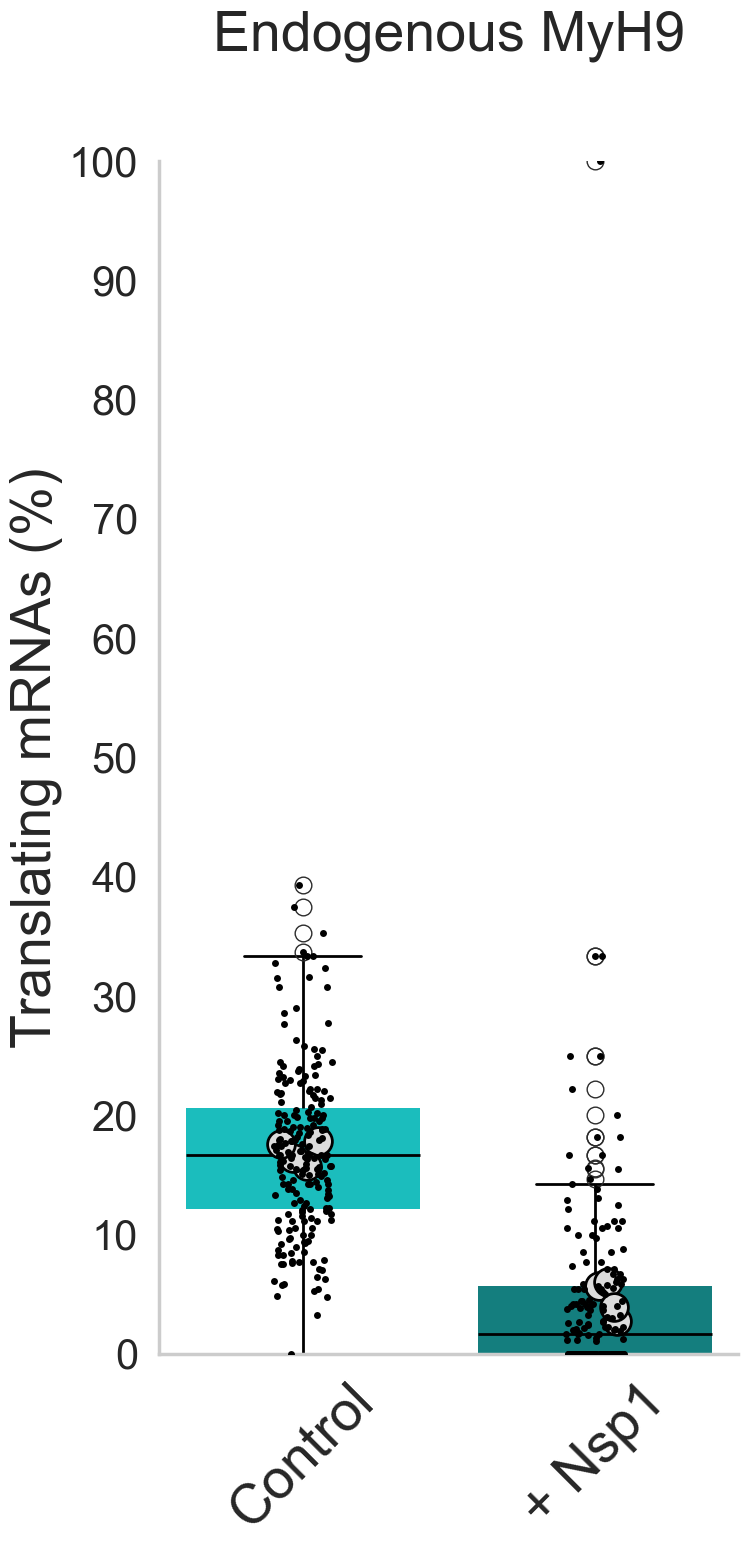

In [35]:
# Plot 5: Translational Efficiency Endogenous Total
import seaborn as sns
import matplotlib.pyplot as plt
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

# Define the order for the x-axis categories
data = df_efficiency
superplot = calculate_grouped_average(data, "Total Translational Efficiency", ["Experimental Group", "Experimental Type", "Replicate Number"])
order = ["Control", "Nsp1"]

# Define the x-tick labels
new_labels = ["Control", "+ Nsp1"]


# Create a figure
fig, ax = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig, top=True, right=True, left=False, bottom=False)

# Plot the Translational Efficiency for each Experimental Group
sns.boxplot(x="Experimental Type", y="Total Translational Efficiency", data=data, order=order, ax=ax, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2))


sns.stripplot(x="Experimental Type", y="Total Translational Efficiency", data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax, zorder=9)

plot_open_circles_with_hue(ax, superplot, order=order, x="Experimental Type", y="Super Total Translational Efficiency", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)


ax.tick_params(axis='both', which='major', labelsize=30)
ax.set_title("Endogenous MyH9", fontsize=40, pad=80)
ax.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax.set_ybound(0, 100)
ax.set_ylabel('Translating mRNAs (%)', fontsize=40)
ax.set_xlabel('')
ax.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Handle the legend
handles, labels = ax.get_legend_handles_labels()
ax.legend().remove()

res1 = print_ttest_summary( x="Experimental Type", y="Total Translational Efficiency", hue="Experimental Group",
            data=data, order=order)
print(res1)

# Show the plot
plt.tight_layout()
plt.show()

# Define the filenames
filename_svg = os.path.join(save_directory + endogenous_folder, "Translation Efficiency Endogenous Total.svg")
filename_png = os.path.join(save_directory + endogenous_folder, "Translation Efficiency Endogenous Total.png")

# Save the figure as SVG
fig.savefig(filename_svg, format='svg', dpi = 300)

# Save the figure as PNG
fig.savefig(filename_png, format='png', dpi = 300)

C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\1383421332.py:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\1383421332.py:49: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(


Across x (within hue):
[hue=Endogenous MyH9] Control vs Nsp1: n=203/183, p=1.44e-37, ****
     test_group                               contrast       x0    x1  \
0  x|within_hue  [hue=Endogenous MyH9] Control vs Nsp1  Control  Nsp1   

              hue0             hue1   n0   n1        pvalue stars  
0  Endogenous MyH9  Endogenous MyH9  203  183  1.443794e-37  ****  


C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\1383421332.py:148: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


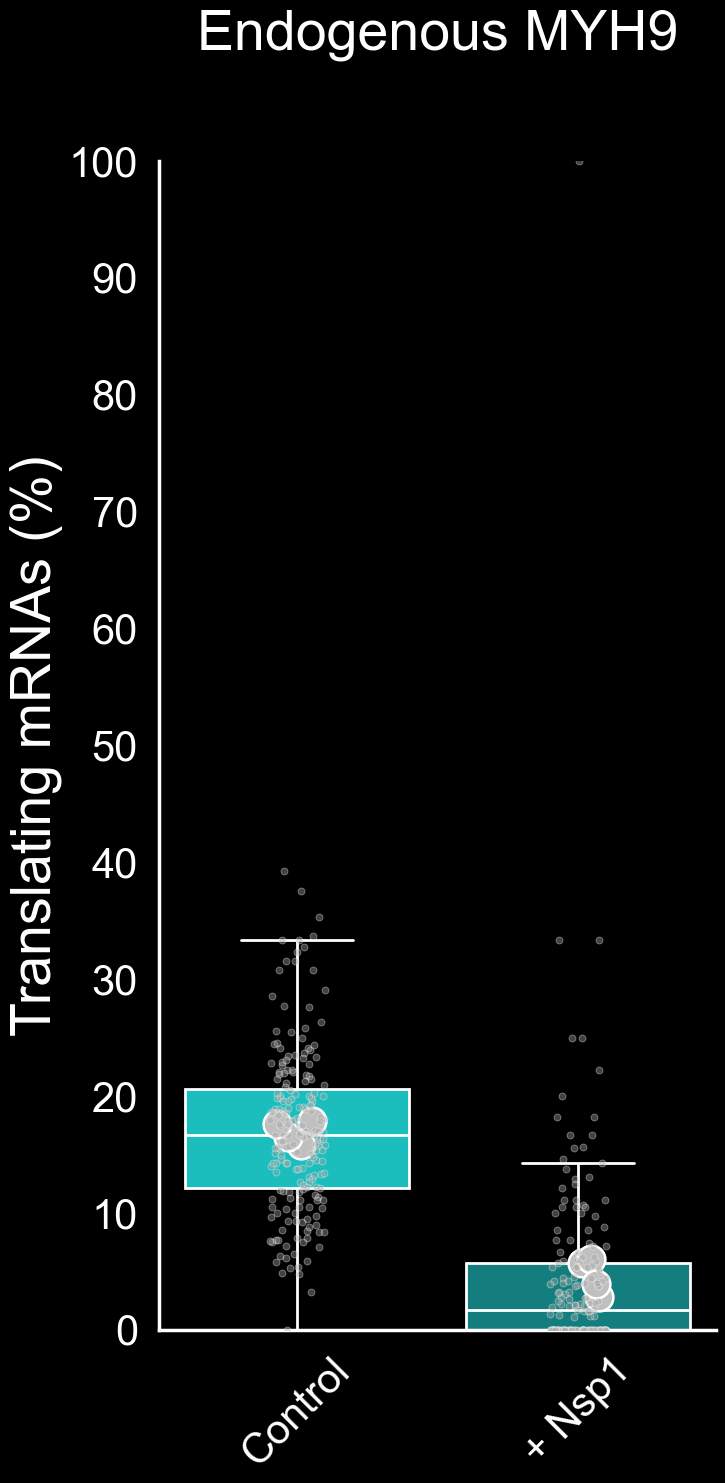

In [42]:
# Plot 5: Translational Efficiency Endogenous Total (Black Background)

import os
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.collections as mcoll
from matplotlib.ticker import MaxNLocator

sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

output_folder = r"Z:\koch\Presentations and Figures\Figures\Endogenous Plots\Black Background"
os.makedirs(output_folder, exist_ok=True)

# Define the order for the x-axis categories
data = df_efficiency
superplot = calculate_grouped_average(
    data,
    "Total Translational Efficiency",
    ["Experimental Group", "Experimental Type", "Replicate Number"]
)
order = ["Control", "Nsp1"]

# Define the x-tick labels
new_labels = ["Control", "+ Nsp1"]

def apply_black_background(ax, fig):
    fig.patch.set_facecolor("black")
    ax.set_facecolor("black")

    ax.tick_params(axis='both', which='major', colors='white', labelsize=30)
    ax.xaxis.label.set_color("white")
    ax.yaxis.label.set_color("white")
    ax.title.set_color("white")

    for spine in ax.spines.values():
        spine.set_color("white")

    for tick in ax.xaxis.get_ticklines() + ax.yaxis.get_ticklines():
        tick.set_color("white")

# Create a figure
fig, ax = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig, top=True, right=True, left=False, bottom=False)

# Plot the Translational Efficiency for each Experimental Group
sns.boxplot(
    x="Experimental Type",
    y="Total Translational Efficiency",
    data=data,
    order=order,
    ax=ax,
    palette=blue_palette,
    boxprops=dict(edgecolor="white", linewidth=2),
    whiskerprops=dict(color="white", linewidth=2),
    capprops=dict(color="white", linewidth=2),
    medianprops=dict(color="white", linewidth=2),
    showfliers=False
)

sns.stripplot(
    x="Experimental Type",
    y="Total Translational Efficiency",
    data=data,
    order=order,
    color="#A6A6A6",
    edgecolor="white",
    linewidth=0.6,
    alpha=0.4,
    size=5,
    jitter=True,
    dodge=True,
    ax=ax,
    zorder=9
)

# Track collections so only the superplot circles get restyled
n_collections_before = len(ax.collections)

plot_open_circles_with_hue(
    ax,
    superplot,
    order=order,
    x="Experimental Type",
    y="Super Total Translational Efficiency",
    hue="Experimental Group",
    jitter=True,
    jitter_strength=0.08,
    random_state=100
)

# Style only the superplot circles
for coll in ax.collections[n_collections_before:]:
    if isinstance(coll, mcoll.PathCollection):
        try:
            coll.set_facecolor("#BFBFBF")
            coll.set_edgecolor("white")
            coll.set_linewidth(1.8)
            coll.set_alpha(1)
        except Exception:
            pass

ax.tick_params(axis='both', which='major', labelsize=30, colors="white")
ax.set_title("Endogenous MYH9", fontsize=40, pad=80, color="white")
ax.set_xticklabels(new_labels, fontsize=40, rotation=45, color="white")
ax.set_ybound(0, 100)
ax.set_ylabel("Translating mRNAs (%)", fontsize=40, color="white")
ax.set_xlabel("")
ax.yaxis.set_major_locator(MaxNLocator(nbins=10))

apply_black_background(ax, fig)

# Handle the legend
if ax.get_legend() is not None:
    ax.legend().remove()

res1 = print_ttest_summary(
    x="Experimental Type",
    y="Total Translational Efficiency",
    hue="Experimental Group",
    data=data,
    order=order
)
print(res1)

# Define the filenames
filename_svg = os.path.join(output_folder, "Translation Efficiency Endogenous Total.svg")
filename_png = os.path.join(output_folder, "Translation Efficiency Endogenous Total.png")

# Save the figure
fig.savefig(
    filename_svg,
    format="svg",
    dpi=300,
    facecolor=fig.get_facecolor(),
    edgecolor="none"
)
fig.savefig(
    filename_png,
    format="png",
    dpi=300,
    facecolor=fig.get_facecolor(),
    edgecolor="none"
)

plt.tight_layout()
plt.show()

C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\2717779709.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Experimental Type", y="Cyto Translational Efficiency", data=data, order=order, ax=ax, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2))
C:\Users\AdamC\AppData\Local\Temp\ipykernel_31408\2717779709.py:23: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(x="Experimental Type", y="Cyto Translational Efficiency", data=data, order=order, ax=ax, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2))
C:\User

Across x (within hue):
[hue=Endogenous MyH9] Control vs Nsp1: n=203/181, p=2.55e-43, ****
     test_group                               contrast       x0    x1  \
0  x|within_hue  [hue=Endogenous MyH9] Control vs Nsp1  Control  Nsp1   

              hue0             hue1   n0   n1        pvalue stars  
0  Endogenous MyH9  Endogenous MyH9  203  181  2.550008e-43  ****  


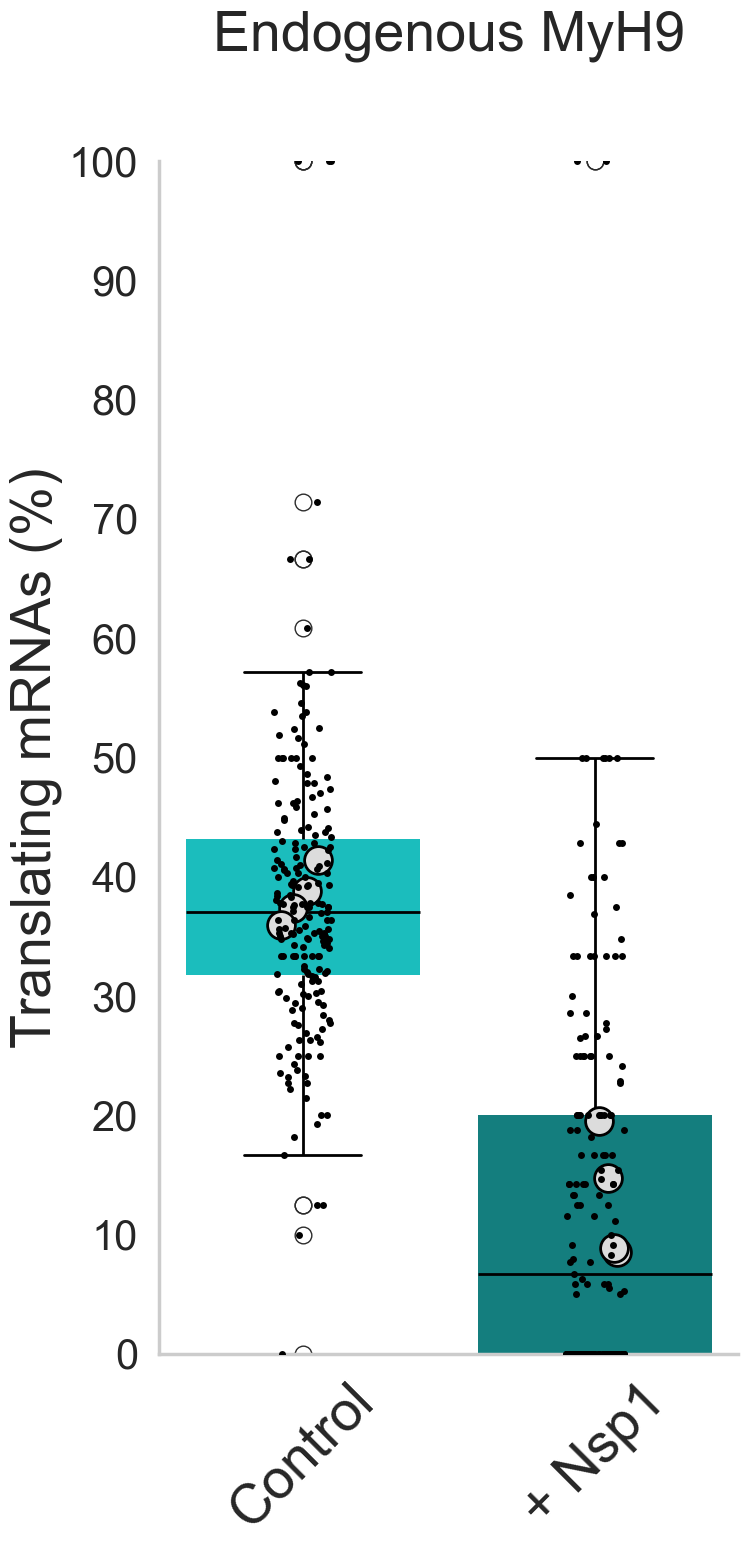

In [36]:
# Plot 6: Translational Efficiency Endogenous Cyto
import seaborn as sns
import matplotlib.pyplot as plt
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

# Define the order for the x-axis categories
data = df_efficiency
superplot = calculate_grouped_average(data, "Cyto Translational Efficiency", ["Experimental Group", "Experimental Type", "Replicate Number"])
order = ["Control", "Nsp1"]

# Define the x-tick labels
new_labels = ["Control", "+ Nsp1"]


# Create a figure
fig, ax = plt.subplots(figsize=(8, 16), constrained_layout=True)

sns.despine(fig=fig, top=True, right=True, left=False, bottom=False)

# Plot the Translational Efficiency for each Experimental Group
sns.boxplot(x="Experimental Type", y="Cyto Translational Efficiency", data=data, order=order, ax=ax, palette= blue_palette, boxprops=dict(linewidth=0), whiskerprops=dict(color="black", linewidth=2), capprops=dict(color="black", linewidth=2), medianprops=dict(color="black", linewidth=2))


sns.stripplot(x="Experimental Type", y="Cyto Translational Efficiency", data=data, order=order, color="black", alpha = 1, size=5, jitter=True, dodge=True, ax=ax, zorder=9)

plot_open_circles_with_hue(ax, superplot, order=order, x="Experimental Type", y="Super Cyto Translational Efficiency", hue="Experimental Group", jitter = True, jitter_strength = 0.08, random_state = 100)


ax.tick_params(axis='both', which='major', labelsize=30)
ax.set_title("Endogenous MyH9", fontsize=40, pad=80)
ax.set_xticklabels(new_labels, fontsize=40, rotation=45)
ax.set_ybound(0, 100)
ax.set_ylabel('Translating mRNAs (%)', fontsize=40)
ax.set_xlabel('')
ax.yaxis.set_major_locator(MaxNLocator(nbins=10))

# Handle the legend
handles, labels = ax.get_legend_handles_labels()
ax.legend().remove()

res1 = print_ttest_summary( x="Experimental Type", y="Cyto Translational Efficiency", hue="Experimental Group",
            data=data, order=order)
print(res1)

# Show the plot
plt.tight_layout()
plt.show()

# Define the filenames
filename_svg = os.path.join(save_directory + endogenous_folder, "Translation Efficiency Endogenous Cyto.svg")
filename_png = os.path.join(save_directory + endogenous_folder, "Translation Efficiency Endogenous Cyto.png")

# Save the figure as SVG
fig.savefig(filename_svg, format='svg', dpi = 300)

# Save the figure as PNG
fig.savefig(filename_png, format='png', dpi = 300)

,Experimental Type,Mean_Total_mRNA,Mean_Cyto_mRNA,Mean_Nuc_mRNA,Cyto Fraction,Nuc Fraction
0,Control,88.698020,39.846535,48.851485,0.449238,0.550762
1,Nsp1,39.071038,9.683060,29.387978,0.247832,0.752168


C:\Users\AdamC\AppData\Local\Temp\ipykernel_32780\3673912532.py:161: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


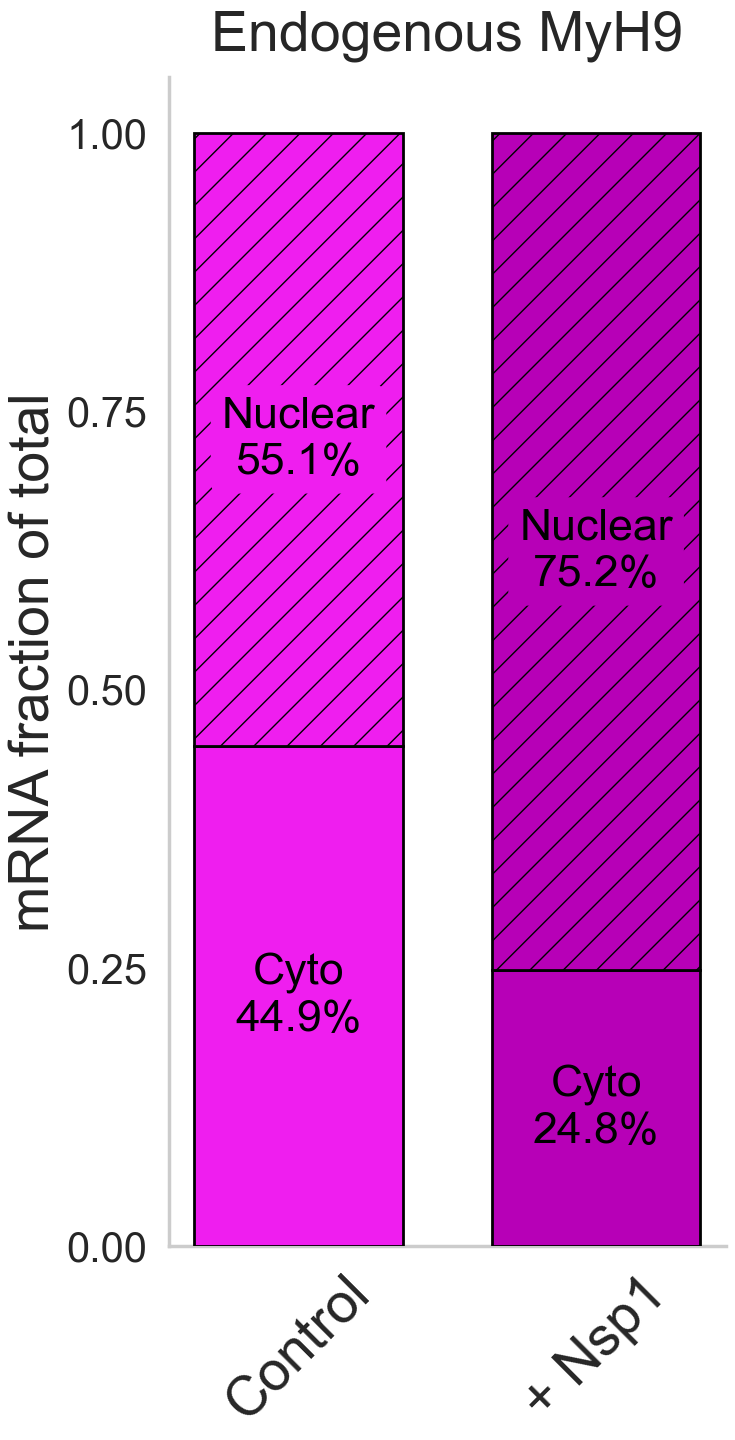

In [50]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# -----------------------------
# Style
# -----------------------------
sns.set(font_scale=1.9)
sns.set_style("whitegrid", {"grid.linestyle": ""})
sns.set_context("poster")

order = ["Control", "Nsp1"]
new_labels = ["Control", "+ Nsp1"]

type_colors = {
    "Control": "#Ef1EEF",
    "Nsp1": "#B700B7",
}

# -----------------------------
# Start from your no-outlier dataframe
# -----------------------------
data = df_no_outliers_total.copy()

data = data[
    (data["Experimental Group"] == "Endogenous MyH9") &
    (data["Experimental Type"].isin(order))
].copy()

# Keep only dates that contain BOTH Control and Nsp1
valid_dates = (
    data.groupby("Date")["Experimental Type"]
    .apply(lambda x: {"Control", "Nsp1"}.issubset(set(x)))
)
valid_dates = valid_dates[valid_dates].index

data = data[data["Date"].isin(valid_dates)].copy()

# -----------------------------
# Summarize mean counts by condition
# -----------------------------
summary = (
    data.groupby("Experimental Type", as_index=False)
    .agg(
        Mean_Total_mRNA=("Total mRNA", "mean"),
        Mean_Cyto_mRNA=("Cyto mRNA", "mean"),
        Mean_Nuc_mRNA=("Nuc mRNA", "mean"),
    )
)

summary["Cyto Fraction"] = summary["Mean_Cyto_mRNA"] / summary["Mean_Total_mRNA"]
summary["Nuc Fraction"] = summary["Mean_Nuc_mRNA"] / summary["Mean_Total_mRNA"]

summary["Experimental Type"] = pd.Categorical(
    summary["Experimental Type"], categories=order, ordered=True
)
summary = summary.sort_values("Experimental Type").reset_index(drop=True)

display(summary)

# -----------------------------
# Plot stacked normalized bars
# -----------------------------
fig, ax = plt.subplots(figsize=(8, 16), constrained_layout=True)
sns.despine(fig=fig, top=True, right=True, left=False, bottom=False)

x = np.arange(len(summary))
bar_width = 0.7

for i, row in summary.iterrows():
    treatment = row["Experimental Type"]
    color = type_colors[treatment]

    cyto_height = row["Cyto Fraction"]
    nuc_height = row["Nuc Fraction"]

    # Cytoplasmic portion: no hatch
    ax.bar(
        x[i],
        cyto_height,
        width=bar_width,
        color=color,
        edgecolor="black",
        linewidth=2,
        hatch=None,
        zorder=3,
    )

    # Nuclear portion: lighter hatch
    ax.bar(
        x[i],
        nuc_height,
        width=bar_width,
        bottom=cyto_height,
        color=color,
        edgecolor="black",
        linewidth=2,
        hatch="/",
        zorder=3,
    )

    # Labels inside bar sections with background boxes
    ax.text(
        x[i],
        cyto_height / 2,
        f"Cyto\n{cyto_height*100:.1f}%",
        ha="center",
        va="center",
        fontsize=32,
        color="black",
        bbox=dict(
            boxstyle="round,pad=0.25",
            facecolor=color,
            edgecolor="none",
            alpha=1.0
        ),
        zorder=5
    )

    ax.text(
        x[i],
        cyto_height + nuc_height / 2,
        f"Nuclear\n{nuc_height*100:.1f}%",
        ha="center",
        va="center",
        fontsize=32,
        color="black",
        bbox=dict(
            boxstyle="round,pad=0.25",
            facecolor=color,
            edgecolor="none",
            alpha=1.0
        ),
        zorder=5
    )

# -----------------------------
# Formatting
# -----------------------------
ax.set_title("Endogenous MyH9", fontsize=40, pad=20)
ax.set_ylabel("mRNA fraction of total", fontsize=40)
ax.set_xlabel("")
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
ax.tick_params(axis="both", which="major", labelsize=30)
ax.set_xticks(x)
ax.set_xticklabels(new_labels, fontsize=40, rotation=45)

# -----------------------------
# Save
# -----------------------------
filename_svg = os.path.join(save_directory + endogenous_folder, "Normalized_Stacked_mRNA_Endogenous.svg")
filename_png = os.path.join(save_directory + endogenous_folder, "Normalized_Stacked_mRNA_Endogenous.png")

fig.savefig(filename_svg, format="svg", dpi=300)
fig.savefig(filename_png, format="png", dpi=300)

plt.tight_layout()
plt.show()